In [1]:
import numpy as np
import torch
import torch.nn as nn
import matplotlib.pyplot as plt

# Examen

**Autor:** Eduardo Henao R.  
**ID:** 1039453805

1. (20\%)Considere un detector que registra el número de partículas que llegan a su superficie durante intervalos de tiempo fijos. Se asume que las detecciones ocurren de manera independiente y que la tasa esperada de llegada depende de una condición experimental $x_{i}$, por ejemplo la intensidad de la fuente, la distancia al detector o el tiempo de exposición.
Bajo estas hipótesis, el número de eventos observados $y_{i}$ se modela como una variable aleatoria de Poisson:

\begin{equation}
p\left(y_{i} \mid x_{i} ; \theta\right)=\frac{h_{\theta}\left(x_{i}\right)^{y_{i}} e^{-h_{\theta}\left(x_{i}\right)}}{y_{i}!}, \quad y_{i}=0,1,2, \ldots \tag{1}
\end{equation}

donde $h_{\theta}\left(x_{i}\right)$ representa la tasa esperada de detecciones. En este primer modelo, suponga que la tasa depende linealmente de $x_{i}$ :

\begin{equation}
h_{\theta}\left(x_{i}\right)=\theta_{0}+\theta_{1} x_{i} . \tag{2}
\end{equation}

Como $h_{\theta}\left(x_{i}\right)$ representa una tasa física, se debe cumplir que

\begin{equation}
h_{\theta}\left(x_{i}\right)>0 \tag{3}
\end{equation}

para todos los datos observados.
    (a) Construya la función de verosimilitud $L(\theta)$ para un conjunto de datos independientes $\left\{\left(x_{i}, y_{i}\right)\right\}_{i=1}^{n}$.
    (b) Determine la log-verosimilitud $\ell(\theta)$ y obtenga la función de coste asociada al principio de máxima verosimilitud.
    (c) Muestre que, salvo constantes independientes de $\theta$, la función de coste puede escribirse como


\begin{equation}
J(\theta)=\sum_{i=1}^{n}\left[h_{\theta}\left(x_{i}\right)-y_{i} \log h_{\theta}\left(x_{i}\right)\right] . \tag{4}
\end{equation}

    (d) Usando $h_{\theta}\left(x_{i}\right)=\theta_{0}+\theta_{1} x_{i}$, calcule el gradiente de $J(\theta)$ respecto a $\theta_{0}$ y $\theta_{1}$.
    (e) Interprete físicamente $h_{\theta}(x), \theta_{0}$ y $\theta_{1}$ en el contexto del detector.

2. (20\%) Backward pass. Considere una red neuronal de una capa oculta que recibe una entrada escalar $x_{i}$ y produce una tasa esperada de conteos mediante una salida positiva:

\begin{equation}
h_{\theta}\left(x_{i}\right)=\exp \left(f_{\theta}\left(x_{i}\right)\right) . \tag{5}
\end{equation}

La red está definida por:

\begin{align}
Z_{i, 1}^{[1]} & =\theta_{1,1}^{[1]} x_{i}+b_{1}^{[1]},  \tag{6}\\
A_{i, 1}^{[1]} & =\sigma\left(Z_{i, 1}^{[1]}\right),  \tag{7}\\
Z_{i, 1}^{[2]} & =\theta_{1,1}^{[2]} A_{i, 1}^{[[]}+b_{1}^{[2]},  \tag{8}\\
h_{\theta}\left(x_{i}\right) & =\exp \left(Z_{i, 1}^{[1]}\right) . \tag{9}
\end{align}

donde $\sigma$ es una función de activación diferenciable. Para un dato $\left(x_{i}, y_{i}\right)$, la función de coste de Poisson, salvo constantes independientes de $\theta$, es


\begin{equation}
J_{i}(\theta)=h_{\theta}\left(x_{i}\right)-y_{i} \log h_{\theta}\left(x_{i}\right) . \tag{10}
\end{equation}

Como $h_{\theta}\left(x_{i}\right)=\exp \left(Z_{i, 1}^{[2]}\right)$, esta función puede escribirse como


\begin{equation}
J_{i}(\theta)=\exp \left(Z_{i, 1}^{[2]}\right)-y_{i} Z_{i, 1}^{[2]} . \tag{11}
\end{equation}

    (a) Calcule el error en la capa de salida:

\begin{equation}
\delta_{i, 1}^{[2]}=\frac{\partial J_{i}}{\partial Z_{i, 1}^{[2]}} . \tag{12}
\end{equation}

    (b) Calcule los gradientes respecto a los parámetros de la capa de salida:

\begin{equation}
\frac{\partial J_{i}}{\partial \theta_{1,1}^{[2]}}, \quad \frac{\partial J_{i}}{\partial b_{1}^{[2]}} . \tag{13}
\end{equation}

    (c) Calcule el error que se propaga hacia la capa oculta:

\begin{equation}
\delta_{i, 1}^{[1]}=\frac{\partial J_{i}}{\partial Z_{i, 1}^{[1]}}=\frac{\partial J_{i}}{\partial Z_{i, 1}^{[2]}} \frac{\partial Z_{i, 1}^{[2]}}{\partial A_{i, 1}^{[1]}} \frac{\partial A_{i, 1}^{[1]}}{\partial Z_{i, 1}^{[1]}} \tag{14}
\end{equation}

    (d) Calcule los gradientes respecto a los parámetros de la primera capa:

\begin{equation}
\frac{\partial J_{i}}{\partial \theta_{1,1}^{[1]}}, \quad \frac{\partial J_{i}}{\partial b_{1}^{[1]}} . \tag{15}
\end{equation}

3. (30\%) Considere una membrana cuadrada de lado unitario, con bordes fijos, cuyos desplazamientos transversales (U(x,y,t)), respecto a su posición de equilibrio, están descritos, en el régimen de pequeñas oscilaciones, por la ecuación de ondas adimensional:

\frac{\partial^{2} U}{\partial t^{2}}=\frac{\partial^{2} U}{\partial x^{2}}+\frac{\partial^{2} U}{\partial y^{2}}

con $U=0$ en los bordes y condiciones iniciales

\begin{gathered}
U(x, y, 0)=\sin (\pi x) \sin (\pi y), \\
U_{t}(x, y, 0)=\sqrt{2} \pi \sin (\pi x) \sin (\pi y) .
\end{gathered}

Aproxime el desplazamiento $U(x, y, t)$ mediante una PINN de la forma

\begin{align}
U_{\theta}(x, y, t)=\sin (\pi x) \sin (\pi y) a_{\theta}(t) .
\end{align}

donde $a_{\theta}(t)$ se representa mediante las siguientes arquitecturas:
Modelo A. Una capa con dos neuronas de activación sinusoidal:

\begin{align}
a_{\theta}(t)=\sum_{j=1}^{2} A_{j} \sin \left(w_{j} t+b_{j}\right) .
\end{align}

Modelo B. Dos capas consecutivas, con una neurona por capa:


\begin{gathered}
h_{1}(t)=\sin \left(w_{1} t+b_{1}\right), \\
a_{\theta}(t)=A \sin \left(w_{2} h_{1}(t)+b_{2}\right) .
\end{gathered}

Parte analítica. Para ambas arquitecturas, reducir la ecuación de ondas a una ecuación diferencial ordinaria, calcular analíticamente las derivadas de las neuronas y construir el residuo físico y la función de pérdida, incorporando las condiciones iniciales.
Parte computacional. Implementar en Python ambas arquitecturas y minimizar sus funciones de pérdida mediante un método de optimización. Comparar gráficamente las soluciones obtenidas con la solución analítica, cuantificar los errores de aproximación y analizar la conservación de la energía mecánica de la membrana. Analice todos los resultados.

**Ayuda:** La energía mecánica total se conserva:

\begin{gathered}
E(t)=\frac{1}{2} \int_{0}^{1} \int_{0}^{1}\left[\left(\frac{\partial U}{\partial t}\right)^{2}+\left(\frac{\partial U}{\partial x}\right)^{2}+\left(\frac{\partial U}{\partial y}\right)^{2}\right] d x d y \\
\frac{d E}{d t}=0
\end{gathered}

4. (30\%) Considere una red de memoria asociativa formada por $N$ neuronas que almacena $P$ patrones binarios. Cada patrón se representa mediante un vector de $N$ componentes, cuyos valores son +1 o -1. Los patrones almacenados se organizan en una matriz $X$ de tamaño $P \times N$, cuyos elementos son

\begin{align}
x_{\mu i} \in\{-1,+1\},
\end{align}

donde $\mu=1, \ldots, P$ identifica el patrón almacenado e $i=1, \ldots, N$ identifica la neurona. El estado de la red se describe mediante un vector $\mathbf{q}=\left(q_{1}, \ldots, q_{N}\right)$, donde $q_{i} \in \mathbb{R}$ representa el estado de la neurona $i$. Inicialmente, la red recibe un patrón binario $\mathbf{q}^{(0)}$, que puede contener errores respecto a uno de los patrones almacenados.
La recuperación de la memoria se realiza mediante la minimización de la función de energía

\begin{align}
E(\mathbf{q})=\frac{1}{2} \sum_{i=1}^{N} q_{i}^{2}-\frac{1}{\beta} \ln \left(\sum_{\mu=1}^{P} \exp \left[\beta \sum_{i=1}^{N} x_{\mu i} q_{i}\right]\right)
\end{align}

donde $\beta>0$ es un parámetro que controla la selectividad de la recuperación. Durante la evolución de la red, los valores $q_{i}$ pueden ser continuos, aunque los patrones almacenados sean binarios.

## Parte analítica

- Calcular las derivadas parciales de la energía respecto a cada componente $q_{i}$ y obtener la expresión del gradiente.
- A partir del descenso de gradiente, deducir la regla de actualización:

\begin{align}
q_{i}^{(t+1)}=q_{i}^{(t)}-\left.\alpha \frac{\partial E}{\partial q_{i}}\right|_{\mathbf{q}=\mathbf{q}^{(t)}},
\end{align}

donde $\alpha>0$ es el tamaño del paso de actualización y $t=0,1,2, \ldots$ representa el número de iteración.
- Considerar el caso $\alpha=1$ y simplificar la regla de actualización. Analizar cómo influye el parámetro $\beta$ en la contribución de los diferentes patrones almacenados, considerando valores pequeños y grandes.

## Parte computacional

- Implementar en Python una red de memoria asociativa que almacene dos patrones binarios correspondientes a las letras J y H, representados mediante imágenes de 8 × 8 píxeles. Cada patrón contiene $N=64$ componentes, donde +1 representa un píxel activo y -1 uno inactivo. Organizar los patrones en una matriz $X$ de tamaño $2 \times 64$.
- Seleccionar uno de los patrones almacenados y generar un estado inicial perturbado mediante la inversión aleatoria de un porcentaje de sus píxeles. Implementar iterativamente la regla de actualización obtenida en la parte analítica, utilizando $\alpha=1$, hasta alcanzar la convergencia o un número máximo de iteraciones.
- Desarrollar experimentos computacionales que permitan:
    (a) Visualizar el patrón original, el patrón perturbado y el estado final de la red, tanto en su representación continua como binaria.
    (b) Estudiar cómo cambia la recuperación al modificar el porcentaje de píxeles perturbados. Realizar varias perturbaciones aleatorias para cada porcentaje y evaluar la calidad de la recuperación.
    (c) Analizar cómo influye el parámetro $\beta$ en la evolución de la energía y en los estados finales de la red. Interpretar los resultados obtenidos.

**Ayuda:** Para evaluar la recuperación, convertir el estado final en un patrón binario según el signo de cada componente y calcular el porcentaje de píxeles que coinciden con el patrón original.

1. (20\%)Considere un detector que registra el número de partículas que llegan a su superficie durante intervalos de tiempo fijos. Se asume que las detecciones ocurren de manera independiente y que la tasa esperada de llegada depende de una condición experimental $x_{i}$, por ejemplo la intensidad de la fuente, la distancia al detector o el tiempo de exposición.
Bajo estas hipótesis, el número de eventos observados $y_{i}$ se modela como una variable aleatoria de Poisson:

\begin{equation}
p\left(y_{i} \mid x_{i} ; \theta\right)=\frac{h_{\theta}\left(x_{i}\right)^{y_{i}} e^{-h_{\theta}\left(x_{i}\right)}}{y_{i}!}, \quad y_{i}=0,1,2, \ldots \tag{1}
\end{equation}

donde $h_{\theta}\left(x_{i}\right)$ representa la tasa esperada de detecciones. En este primer modelo, suponga que la tasa depende linealmente de $x_{i}$ :

\begin{equation}
h_{\theta}\left(x_{i}\right)=\theta_{0}+\theta_{1} x_{i} . \tag{2}
\end{equation}

Como $h_{\theta}\left(x_{i}\right)$ representa una tasa física, se debe cumplir que

\begin{equation}
h_{\theta}\left(x_{i}\right)>0 \tag{3}
\end{equation}

para todos los datos observados.
    (a) Construya la función de verosimilitud $L(\theta)$ para un conjunto de datos independientes $\left\{\left(x_{i}, y_{i}\right)\right\}_{i=1}^{n}$.
    (b) Determine la log-verosimilitud $\ell(\theta)$ y obtenga la función de coste asociada al principio de máxima verosimilitud.
    (c) Muestre que, salvo constantes independientes de $\theta$, la función de coste puede escribirse como


\begin{equation}
J(\theta)=\sum_{i=1}^{n}\left[h_{\theta}\left(x_{i}\right)-y_{i} \log h_{\theta}\left(x_{i}\right)\right] . \tag{4}
\end{equation}

    (d) Usando $h_{\theta}\left(x_{i}\right)=\theta_{0}+\theta_{1} x_{i}$, calcule el gradiente de $J(\theta)$ respecto a $\theta_{0}$ y $\theta_{1}$.
    (e) Interprete físicamente $h_{\theta}(x), \theta_{0}$ y $\theta_{1}$ en el contexto del detector.

2. (20\%) Backward pass. Considere una red neuronal de una capa oculta que recibe una entrada escalar $x_{i}$ y produce una tasa esperada de conteos mediante una salida positiva:

\begin{equation}
h_{\theta}\left(x_{i}\right)=\exp \left(f_{\theta}\left(x_{i}\right)\right) . \tag{5}
\end{equation}

La red está definida por:

\begin{align}
Z_{i, 1}^{[1]} & =\theta_{1,1}^{[1]} x_{i}+b_{1}^{[1]},  \tag{6}\\
A_{i, 1}^{[1]} & =\sigma\left(Z_{i, 1}^{[1]}\right),  \tag{7}\\
Z_{i, 1}^{[2]} & =\theta_{1,1}^{[2]} A_{i, 1}^{[[]}+b_{1}^{[2]},  \tag{8}\\
h_{\theta}\left(x_{i}\right) & =\exp \left(Z_{i, 1}^{[1]}\right) . \tag{9}
\end{align}

donde $\sigma$ es una función de activación diferenciable. Para un dato $\left(x_{i}, y_{i}\right)$, la función de coste de Poisson, salvo constantes independientes de $\theta$, es


\begin{equation}
J_{i}(\theta)=h_{\theta}\left(x_{i}\right)-y_{i} \log h_{\theta}\left(x_{i}\right) . \tag{10}
\end{equation}

Como $h_{\theta}\left(x_{i}\right)=\exp \left(Z_{i, 1}^{[2]}\right)$, esta función puede escribirse como


\begin{equation}
J_{i}(\theta)=\exp \left(Z_{i, 1}^{[2]}\right)-y_{i} Z_{i, 1}^{[2]} . \tag{11}
\end{equation}

    (a) Calcule el error en la capa de salida:

\begin{equation}
\delta_{i, 1}^{[2]}=\frac{\partial J_{i}}{\partial Z_{i, 1}^{[2]}} . \tag{12}
\end{equation}

    (b) Calcule los gradientes respecto a los parámetros de la capa de salida:

\begin{equation}
\frac{\partial J_{i}}{\partial \theta_{1,1}^{[2]}}, \quad \frac{\partial J_{i}}{\partial b_{1}^{[2]}} . \tag{13}
\end{equation}

    (c) Calcule el error que se propaga hacia la capa oculta:

\begin{equation}
\delta_{i, 1}^{[1]}=\frac{\partial J_{i}}{\partial Z_{i, 1}^{[1]}}=\frac{\partial J_{i}}{\partial Z_{i, 1}^{[2]}} \frac{\partial Z_{i, 1}^{[2]}}{\partial A_{i, 1}^{[1]}} \frac{\partial A_{i, 1}^{[1]}}{\partial Z_{i, 1}^{[1]}} \tag{14}
\end{equation}

    (d) Calcule los gradientes respecto a los parámetros de la primera capa:

\begin{equation}
\frac{\partial J_{i}}{\partial \theta_{1,1}^{[1]}}, \quad \frac{\partial J_{i}}{\partial b_{1}^{[1]}} . \tag{15}
\end{equation}

3. (30\%) Considere una membrana cuadrada de lado unitario, con bordes fijos, cuyos desplazamientos transversales (U(x,y,t)), respecto a su posición de equilibrio, están descritos, en el régimen de pequeñas oscilaciones, por la ecuación de ondas adimensional:

\frac{\partial^{2} U}{\partial t^{2}}=\frac{\partial^{2} U}{\partial x^{2}}+\frac{\partial^{2} U}{\partial y^{2}}

con $U=0$ en los bordes y condiciones iniciales

\begin{gathered}
U(x, y, 0)=\sin (\pi x) \sin (\pi y), \\
U_{t}(x, y, 0)=\sqrt{2} \pi \sin (\pi x) \sin (\pi y) .
\end{gathered}

Aproxime el desplazamiento $U(x, y, t)$ mediante una PINN de la forma

\begin{align}
U_{\theta}(x, y, t)=\sin (\pi x) \sin (\pi y) a_{\theta}(t) .
\end{align}

donde $a_{\theta}(t)$ se representa mediante las siguientes arquitecturas:
Modelo A. Una capa con dos neuronas de activación sinusoidal:

\begin{align}
a_{\theta}(t)=\sum_{j=1}^{2} A_{j} \sin \left(w_{j} t+b_{j}\right) .
\end{align}

Modelo B. Dos capas consecutivas, con una neurona por capa:


\begin{gathered}
h_{1}(t)=\sin \left(w_{1} t+b_{1}\right), \\
a_{\theta}(t)=A \sin \left(w_{2} h_{1}(t)+b_{2}\right) .
\end{gathered}

Parte analítica. Para ambas arquitecturas, reducir la ecuación de ondas a una ecuación diferencial ordinaria, calcular analíticamente las derivadas de las neuronas y construir el residuo físico y la función de pérdida, incorporando las condiciones iniciales.
Parte computacional. Implementar en Python ambas arquitecturas y minimizar sus funciones de pérdida mediante un método de optimización. Comparar gráficamente las soluciones obtenidas con la solución analítica, cuantificar los errores de aproximación y analizar la conservación de la energía mecánica de la membrana. Analice todos los resultados.

**Ayuda:** La energía mecánica total se conserva:

\begin{gathered}
E(t)=\frac{1}{2} \int_{0}^{1} \int_{0}^{1}\left[\left(\frac{\partial U}{\partial t}\right)^{2}+\left(\frac{\partial U}{\partial x}\right)^{2}+\left(\frac{\partial U}{\partial y}\right)^{2}\right] d x d y \\
\frac{d E}{d t}=0
\end{gathered}

4. (30\%) Considere una red de memoria asociativa formada por $N$ neuronas que almacena $P$ patrones binarios. Cada patrón se representa mediante un vector de $N$ componentes, cuyos valores son +1 o -1. Los patrones almacenados se organizan en una matriz $X$ de tamaño $P \times N$, cuyos elementos son

\begin{align}
x_{\mu i} \in\{-1,+1\},
\end{align}

donde $\mu=1, \ldots, P$ identifica el patrón almacenado e $i=1, \ldots, N$ identifica la neurona. El estado de la red se describe mediante un vector $\mathbf{q}=\left(q_{1}, \ldots, q_{N}\right)$, donde $q_{i} \in \mathbb{R}$ representa el estado de la neurona $i$. Inicialmente, la red recibe un patrón binario $\mathbf{q}^{(0)}$, que puede contener errores respecto a uno de los patrones almacenados.
La recuperación de la memoria se realiza mediante la minimización de la función de energía

\begin{align}
E(\mathbf{q})=\frac{1}{2} \sum_{i=1}^{N} q_{i}^{2}-\frac{1}{\beta} \ln \left(\sum_{\mu=1}^{P} \exp \left[\beta \sum_{i=1}^{N} x_{\mu i} q_{i}\right]\right)
\end{align}

donde $\beta>0$ es un parámetro que controla la selectividad de la recuperación. Durante la evolución de la red, los valores $q_{i}$ pueden ser continuos, aunque los patrones almacenados sean binarios.

## Parte analítica

- Calcular las derivadas parciales de la energía respecto a cada componente $q_{i}$ y obtener la expresión del gradiente.
- A partir del descenso de gradiente, deducir la regla de actualización:

\begin{align}
q_{i}^{(t+1)}=q_{i}^{(t)}-\left.\alpha \frac{\partial E}{\partial q_{i}}\right|_{\mathbf{q}=\mathbf{q}^{(t)}},
\end{align}

donde $\alpha>0$ es el tamaño del paso de actualización y $t=0,1,2, \ldots$ representa el número de iteración.
- Considerar el caso $\alpha=1$ y simplificar la regla de actualización. Analizar cómo influye el parámetro $\beta$ en la contribución de los diferentes patrones almacenados, considerando valores pequeños y grandes.

## Parte computacional

- Implementar en Python una red de memoria asociativa que almacene dos patrones binarios correspondientes a las letras J y H, representados mediante imágenes de 8 × 8 píxeles. Cada patrón contiene $N=64$ componentes, donde +1 representa un píxel activo y -1 uno inactivo. Organizar los patrones en una matriz $X$ de tamaño $2 \times 64$.
- Seleccionar uno de los patrones almacenados y generar un estado inicial perturbado mediante la inversión aleatoria de un porcentaje de sus píxeles. Implementar iterativamente la regla de actualización obtenida en la parte analítica, utilizando $\alpha=1$, hasta alcanzar la convergencia o un número máximo de iteraciones.
- Desarrollar experimentos computacionales que permitan:
    (a) Visualizar el patrón original, el patrón perturbado y el estado final de la red, tanto en su representación continua como binaria.
    (b) Estudiar cómo cambia la recuperación al modificar el porcentaje de píxeles perturbados. Realizar varias perturbaciones aleatorias para cada porcentaje y evaluar la calidad de la recuperación.
    (c) Analizar cómo influye el parámetro $\beta$ en la evolución de la energía y en los estados finales de la red. Interpretar los resultados obtenidos.

**Ayuda:** Para evaluar la recuperación, convertir el estado final en un patrón binario según el signo de cada componente y calcular el porcentaje de píxeles que coinciden con el patrón original.

## 1. Estimación por Máxima Verosimilitud (MLE) bajo Distribución de Poisson

Supongamos que las observaciones $\{(x_i, y_i)\}_{i=1}^{n}$ son estadísticamente independientes y siguen una distribución de Poisson. Bajo la asunción *Naive Bayes*, la función de verosimilitud es el producto de las probabilidades individuales:

$$L(\theta) = \prod_{i=1}^{n} p(y_i \mid x_i, \theta) = \prod_{i=1}^{n} \frac{h_\theta(x_i)^{y_i} e^{-h_\theta(x_i)}}{y_i!}$$

donde el modelo lineal para la tasa esperada está dado por $h_\theta(x_i) = \theta_0 + \theta_1 x_i > 0$.

Aplicando el logaritmo natural, la log-verosimilitud convierte la productoria en una sumatoria:

$$\begin{aligned}
\ell(\theta) = \ln [L(\theta)] &= \ln \left[ \prod_{i=1}^{n} \frac{h_\theta(x_i)^{y_i} e^{-h_\theta(x_i)}}{y_i!} \right] \\
&= \sum_{i=1}^{n} \left[ y_i \ln h_\theta(x_i) - h_\theta(x_i) - \ln(y_i!) \right]
\end{aligned}$$

De acuerdo con el criterio de Estimación por Máxima Verosimilitud (EMV / MLE), maximizar $\ell(\theta)$ equivale a minimizar $-\ell(\theta)$. Además, se pueden ignorar los términos independientes de $\theta$, dado que $\frac{\partial [\ln(y_i!)]}{\partial \theta} = 0$:

$$\hat{\theta}_{\text{MLE}} = \arg\max_{\theta \in \Theta} [\ell(\theta)] \iff \arg\min_{\theta \in \Theta} [-\ell(\theta)]$$

Se define entonces la función de costo $J(\theta)$ como:

$$J(\theta) := \sum_{i=1}^{n} \left[ h_\theta(x_i) - y_i \ln h_\theta(x_i) \right]$$

### Cálculo del Gradiente e Interpretación Física

El gradiente de la función de costo respecto a un parámetro $\theta_k$ es:

$$\frac{\partial J}{\partial \theta_k} = \sum_{i=1}^{n} \frac{\partial}{\partial \theta_k} \left[ h_\theta(x_i) - y_i \ln h_\theta(x_i) \right] = \sum_{i=1}^{n} \left[ 1 - \frac{y_i}{h_\theta(x_i)} \right] \frac{\partial h_\theta(x_i)}{\partial \theta_k}$$

Para el modelo lineal $h_\theta(x_i) = \theta_0 + \theta_1 x_i$, las derivadas parciales son:

$$\frac{\partial h_\theta(x_i)}{\partial \theta_k} = \frac{\partial}{\partial \theta_k} [\theta_0 + \theta_1 x_i] \implies \begin{cases} \frac{\partial h_\theta(x_i)}{\partial \theta_0} = 1 \\ \frac{\partial h_\theta(x_i)}{\partial \theta_1} = x_i \end{cases}$$

**Interpretación de los parámetros:**
* **$h_\theta(x_i)$**: Representa la tasa de cuentas esperada según el modelo, verificándose que $h_\theta(0) = \theta_0$.
* **Tasa de fondo ($\theta_0$)**: Si la condición experimental $x_i$ es nula, sin una tasa de fondo $\theta_0$, el modelo no sería adecuado ya que la predicción también se anularía ($\theta_0 = 0 \implies h_\theta(x_i = 0) = 0$).
* **Proporcionalidad ($\theta_1$)**: Representa una constante de proporcionalidad de primer orden asociada al comportamiento lineal de la condición experimental $x_i$. Definir $h_\theta(x_i) = \theta_0 + \theta_1 x_i$ describe un hiperplano de la forma más general.

Sustituyendo el modelo lineal, las componentes explícitas del gradiente resultan en:

$$\frac{\partial J}{\partial \theta_0} = \sum_{i=1}^{n} \left[ \left(\frac{\theta_0 + \theta_1 x_i}{\theta_0 + \theta_1 x_i}\right) - \left(\frac{y_i}{\theta_0 + \theta_1 x_i}\right) \right] = \sum_{i=1}^{n} \left[ \frac{\theta_0 + \theta_1 x_i - y_i}{\theta_0 + \theta_1 x_i} \right]$$

$$\frac{\partial J}{\partial \theta_1} = \sum_{i=1}^{n} x_i \left[ \frac{\theta_0 + \theta_1 x_i - y_i}{\theta_0 + \theta_1 x_i} \right]$$

---

## 2. Retropropagación (Backpropagation) con Función de Pérdida de Poisson

Partiendo de la distribución de probabilidad condicional de Poisson y su log-verosimilitud negativa para la observación $i$-ésima:

$$P(Y = y_i \mid x_i) = \frac{h_\theta(x_i)^{y_i} \exp(-h_\theta(x_i))}{y_i!}$$

$$-\ln P(Y = y_i \mid x_i) = -y_i \ln h_\theta(x_i) + h_\theta(x_i) + \underbrace{\ln(y_i!)}_{\nabla_\theta \to 0}$$

Definimos la pérdida individual $J_i(\theta)$ parametrizando la salida de la red mediante la función de enlace canónica exponencial $h_\theta(x_i) = \exp\left(z_{i,1}^{[2]}\right)$:

$$J_i(\theta) = \underbrace{h_\theta(x_i)}_{\exp\left(z_{i,1}^{[2]}\right)} - y_i \underbrace{\ln h_\theta(x_i)}_{z_{i,1}^{[2]}} = \exp\left(z_{i,1}^{[2]}\right) - y_i z_{i,1}^{[2]}$$

donde el parámetro natural viene dado por:

$$\eta_{i,1} = z_{i,1}^{[2]} = \ln h_\theta(x_i)$$

*(Nota: En modelos de clasificación binaria con probabilidad $p_i \equiv P(Y = 1 \mid x_i)$, el parámetro natural análogo se conoce como log-momio o logit: $\ln\left(\frac{p_i}{1 - p_i}\right)$).*

### Propagación del Error y Cálculo de Gradientes

* **Error en la capa de salida ($\delta_{i,1}^{[2]}$):**

$$\delta_{i,1}^{[2]} = \frac{\partial J_i}{\partial \eta_{i,1}} = \frac{\partial}{\partial \eta_{i,1}} \left[ e^{\eta_{i,1}} - y_i \eta_{i,1} \right] = e^{\eta_{i,1}} - y_i = h_\theta(x_i) - y_i$$

* **Gradiente en la capa de salida:**
  Dadas las pre-activaciones $z_{i,1}^{[2]} = \theta_{1,1}^{[2]} A_{i,1}^{[1]} + b_1^{[2]}$ y $z_{i,1}^{[1]} = \theta_{1,1}^{[1]} x_i + b_1^{[1]}$, con activación oculta $A_{i,1}^{[1]} = \sigma\left(z_{i,1}^{[1]}\right)$:

$$\frac{\partial J_i}{\partial \theta_{1,1}^{[2]}} = \frac{\partial J_i}{\partial z_{i,1}^{[2]}} \cdot \frac{\partial z_{i,1}^{[2]}}{\partial \theta_{1,1}^{[2]}} = \delta_{i,1}^{[2]} A_{i,1}^{[1]} = \left[ h_\theta(x_i) - y_i \right] \sigma\left(z_{i,1}^{[1]}\right)$$

$$\frac{\partial J_i}{\partial b_1^{[2]}} = \frac{\partial J_i}{\partial z_{i,1}^{[2]}} \cdot \underbrace{\frac{\partial z_{i,1}^{[2]}}{\partial b_1^{[2]}}}_{=1} = \delta_{i,1}^{[2]} = h_\theta(x_i) - y_i$$

* **Backward pass (Error propagado hacia la capa oculta):**
  Aplicando la regla de la cadena:

$$\delta_{i,1}^{[1]} = \frac{\partial J_i}{\partial z_{i,1}^{[1]}} = \underbrace{\left[ \frac{\partial J_i}{\partial z_{i,1}^{[2]}} \right]}_{\delta_{i,1}^{[2]}} \underbrace{\left[ \frac{\partial z_{i,1}^{[2]}}{\partial A_{i,1}^{[1]}} \right]}_{\theta_{1,1}^{[2]}} \underbrace{\left[ \frac{\partial A_{i,1}^{[1]}}{\partial z_{i,1}^{[1]}} \right]}_{\sigma'\left(z_{i,1}^{[1]}\right)}$$

$$\delta_{i,1}^{[1]} = \delta_{i,1}^{[2]} \theta_{1,1}^{[2]} \sigma'\left(z_{i,1}^{[1]}\right) = \left[ h_\theta(x_i) - y_i \right] \theta_{1,1}^{[2]} \sigma'\left(z_{i,1}^{[1]}\right)$$

* **Gradiente en la capa de entrada (oculta):**
  A partir de $z_{i,1}^{[1]} = \theta_{1,1}^{[1]} x_i + b_1^{[1]}$:

$$\frac{\partial J_i}{\partial \theta_{1,1}^{[1]}} = \left[ \frac{\partial J_i}{\partial z_{i,1}^{[1]}} \right] \left[ \frac{\partial z_{i,1}^{[1]}}{\partial \theta_{1,1}^{[1]}} \right] = \delta_{i,1}^{[1]} x_i = \left[ h_\theta(x_i) - y_i \right] \theta_{1,1}^{[2]} \sigma'\left(z_{i,1}^{[1]}\right) x_i$$

$$\frac{\partial J_i}{\partial b_1^{[1]}} = \left[ \frac{\partial J_i}{\partial z_{i,1}^{[1]}} \right] \underbrace{\left[ \frac{\partial z_{i,1}^{[1]}}{\partial b_1^{[1]}} \right]}_{=1} = \delta_{i,1}^{[1]} = \left[ h_\theta(x_i) - y_i \right] \theta_{1,1}^{[2]} \sigma'\left(z_{i,1}^{[1]}\right)$$

---

## 3. Redes Neuronales Informadas por la Física (PINN): Ecuación de Onda en Membrana Cuadrada

Consideramos la ecuación de onda bidimensional:

$$\frac{\partial^2 U}{\partial t^2}(x, y, t) = \frac{\partial^2 U}{\partial x^2} + \frac{\partial^2 U}{\partial y^2}$$

Sujeta a las condiciones de una membrana cuadrada unitaria mediante el *ansatz* de separación de variables:

$$\begin{cases}
U = 0 & \text{nulo en los bordes } \forall x, y \in \{0, 1\} \\
U(x, y, 0) = \sin(\pi x)\sin(\pi y) & \text{condición inicial de posición} \\
U_t(x, y, 0) = \sqrt{2}\pi U(x, y, 0) & \text{condición inicial de velocidad} \\
U_\theta(x, y, t) = U(x, y, 0) a_\theta(t) & \text{solución propuesta}
\end{cases}$$

Por construcción del *ansatz*, se satisface exactamente la condición de frontera, de modo que $[U_\theta = 0, \ J_{\text{frontera}} = 0] \ \forall x, y \in \{0, 1\}$.

Se estudian dos arquitecturas neuronales para la función temporal $a_\theta(t)$:
1. **Modelo A (una capa con dos neuronas):** $a_\theta(t) = \sum_{j=1}^{2} A_j \sin(\omega_j t + b_j)$
2. **Modelo B (dos capas con una neurona por capa):** $a_\theta(t) = A \sin[\omega_2 h_1(t) + b_2]$, donde $h_1(t) = \sin(\omega_1 t + b_1)$

### Derivadas Parciales y Reducción al Oscilador Armónico

Calculando las derivadas parciales de $U_\theta(x, y, t) = \sin(\pi x)\sin(\pi y)a_\theta(t)$:

$$\frac{\partial U_\theta}{\partial t} = \sin(\pi x)\sin(\pi y)\dot{a}_\theta(t), \quad \frac{\partial^2 U_\theta}{\partial t^2} = \sin(\pi x)\sin(\pi y)\ddot{a}_\theta(t)$$

$$\frac{\partial U_\theta}{\partial x} = \pi \cos(\pi x)\sin(\pi y)a_\theta(t), \quad \frac{\partial^2 U_\theta}{\partial x^2} = -\pi^2 \sin(\pi x)\sin(\pi y)a_\theta(t)$$

$$\frac{\partial U_\theta}{\partial y} = \pi \sin(\pi x)\cos(\pi y)a_\theta(t), \quad \frac{\partial^2 U_\theta}{\partial y^2} = -\pi^2 \sin(\pi x)\sin(\pi y)a_\theta(t)$$

Sustituyendo en la ecuación de onda:

$$\sin(\pi x)\sin(\pi y)\ddot{a}_\theta(t) = -2\pi^2 \sin(\pi x)\sin(\pi y)a_\theta(t)$$

$$[\sin(\pi x)\sin(\pi y)] \left[ \ddot{a}_\theta(t) + 2\pi^2 a_\theta(t) \right] = 0$$

Para un oscilador armónico simple se cumple:

$$\ddot{a}_\theta(t) + \omega_0^2 a_\theta(t) = 0 \implies \omega_0^2 \equiv 2\pi^2 \implies \omega_0 = \sqrt{2}\pi$$

Evaluando las condiciones iniciales en $t = 0$:

$$U_\theta(x, y, 0) = \sin(\pi x)\sin(\pi y)a_\theta(0) = \sin(\pi x)\sin(\pi y) \implies a_\theta(0) = 1$$

$$\frac{\partial U_\theta}{\partial t}(x, y, 0) = \sin(\pi x)\sin(\pi y)\dot{a}_\theta(0) = \underbrace{\sqrt{2}\pi \sin(\pi x)\sin(\pi y)}_{U_t = \sqrt{2}\pi U(x, y, 0)} \implies \dot{a}_\theta(0) = \sqrt{2}\pi$$

### Conservación de la Energía Mecánica

La energía mecánica total del sistema se conserva ($\frac{dE_\theta(t)}{dt} = 0$):

$$E_\theta(t) = \frac{1}{2} \int_0^1 \int_0^1 \left[ \left(\frac{\partial U_\theta}{\partial x}\right)^2 + \left(\frac{\partial U_\theta}{\partial y}\right)^2 + \left(\frac{\partial U_\theta}{\partial t}\right)^2 \right] dx \, dy$$

Utilizando las propiedades de ortonormalidad en el intervalo $[0, 1]$:

$$\int_0^1 \sin^2(\pi z) \, dz = \frac{1}{2}, \quad \int_0^1 \cos^2(\pi z) \, dz = \frac{1}{2}$$

Integrando cada término espacialmente (para $z \in \{x, y\}$):

$$\int_0^1 \int_0^1 \left(\frac{\partial U_\theta}{\partial t}\right)^2 dx \, dy = \int_0^1 \int_0^1 \left(\sin(\pi x)\sin(\pi y)\dot{a}_\theta(t)\right)^2 dx \, dy = \frac{1}{2} \cdot \frac{1}{2} \cdot \dot{a}_\theta^2(t) = \frac{1}{4}\dot{a}_\theta^2(t)$$

$$\int_0^1 \int_0^1 \left(\frac{\partial U_\theta}{\partial z}\right)^2 dx \, dy = \frac{1}{2} \cdot \frac{1}{2} \cdot \pi^2 a_\theta^2(t) = \frac{\pi^2}{4}a_\theta^2(t)$$

Por lo tanto, la energía en función del tiempo queda expresada como:

$$E_\theta(t) = \frac{1}{2} \cdot \frac{1}{4} \left[ \dot{a}_\theta^2(t) + \pi^2 a_\theta^2(t) + \pi^2 a_\theta^2(t) \right] = \frac{1}{8} \left[ \dot{a}_\theta^2(t) + 2\pi^2 a_\theta^2(t) \right]$$

Verificando su derivada temporal:

$$\frac{dE_\theta}{dt} = \frac{1}{8} \frac{d}{dt} \left[ \dot{a}_\theta^2(t) + 2\pi^2 a_\theta^2(t) \right] = \frac{\dot{a}_\theta(t)}{4} \left[ \ddot{a}_\theta(t) + 2\pi^2 a_\theta(t) \right] = 0$$

A partir de las condiciones iniciales en $t = 0$ ($a_\theta(0) = 1, \ \dot{a}_\theta(0) = \sqrt{2}\pi, \ \omega_0^2 = 2\pi^2$), el valor constante de la energía es:

$$E_0 = \frac{1}{8} \left[ 2\pi^2 + 2\pi^2 \right] = \frac{\pi^2}{2} = \frac{\omega_0^2}{4}$$

### Formulación de Residuos PINN por Modelo

Definimos el residuo temporal $r_\theta(t)$ y el residuo espaciotemporal $R_\theta(x, y, t)$:

$$r_\theta(t) = \mathcal{N}[U_\theta] - f = \ddot{a}_\theta(t) + 2\pi^2 a_\theta(t)$$

$$R_\theta(x, y, t) = \sin(\pi x)\sin(\pi y) r_\theta(t)$$

#### Modelo A
* **Conjunto de parámetros:** $\theta_A = \{A_1, A_2, \omega_1, \omega_2, b_1, b_2\}$
* **Dinámica y derivadas:**

$$a_\theta(t) = \sum_{j=1}^{2} A_j \sin(\omega_j t + b_j)$$

$$\dot{a}_\theta(t) = \sum_{j=1}^{2} A_j \omega_j \cos(\omega_j t + b_j), \quad \ddot{a}_\theta(t) = -\sum_{j=1}^{2} A_j \omega_j^2 \sin(\omega_j t + b_j)$$

* **Condiciones iniciales y residuo:**

$$a_\theta(0) = \sum_{j=1}^{2} A_j \sin(b_j), \quad \dot{a}_\theta(0) = \sum_{j=1}^{2} A_j \omega_j \cos(b_j)$$

$$r_\theta^{(A)}(t) = \ddot{a}_\theta(t) + 2\pi^2 a_\theta(t) = \sum_{j=1}^{2} A_j \left(2\pi^2 - \omega_j^2\right) \sin(\omega_j t + b_j)$$

> **Nota:** Si $\omega_k = \sqrt{2}\pi \ \forall k \in \{1, 2\}$, el Modelo A contiene exactamente la solución analítica para todo $t$, anulando idénticamente el residuo bajo esas condiciones.

#### Modelo B
* **Conjunto de parámetros:** $\theta_B = \{A, \omega_1, b_1, \omega_2, b_2\}$
* **Neurona oculta $h_1(t)$:**

$$h_1(t) = \sin(\omega_1 t + b_1)$$

$$\dot{h}_1(t) = \omega_1 \cos(\omega_1 t + b_1), \quad \ddot{h}_1(t) = -\omega_1^2 \sin(\omega_1 t + b_1) = -\omega_1^2 h_1(t)$$

* **Neurona de salida $a_\theta(t) = A \sin(\omega_2 h_1(t) + b_2)$:**

$$\begin{aligned}
\dot{a}_\theta(t) &= A \omega_2 \dot{h}_1(t) \cos(\omega_2 h_1(t) + b_2) \\
&= A \omega_1 \omega_2 \cos(\omega_1 t + b_1) \cos\left[\omega_2 \sin(\omega_1 t + b_1) + b_2\right]
\end{aligned}$$

$$\begin{aligned}
\ddot{a}_\theta(t) &= A \omega_2 \left[ \ddot{h}_1(t) \cos(\omega_2 h_1(t) + b_2) - \omega_2 \dot{h}_1^2(t) \sin(\omega_2 h_1(t) + b_2) \right] \\
&= -A \omega_1^2 \omega_2 \Big[ \sin(\omega_1 t + b_1) \cos\left[\omega_2 \sin(\omega_1 t + b_1) + b_2\right] \\
&\quad + \omega_2 \cos^2(\omega_1 t + b_1) \sin\left[\omega_2 \sin(\omega_1 t + b_1) + b_2\right] \Big]
\end{aligned}$$

* **Condiciones iniciales y residuo:**

$$a_\theta(0) = A \sin\left[\omega_2 \sin(b_1) + b_2\right]$$

$$\dot{a}_\theta(0) = A \omega_1 \omega_2 \cos(b_1) \cos\left[\omega_2 \sin(b_1) + b_2\right]$$

$$\begin{aligned}
r_\theta^{(B)}(t) &= A \left[ 2\pi^2 - \omega_1^2 \omega_2^2 \cos^2(\omega_1 t + b_1) \right] \sin\left[\omega_2 \sin(\omega_1 t + b_1) + b_2\right] \\
&\quad - A \omega_1^2 \omega_2 \sin(\omega_1 t + b_1) \cos\left[\omega_2 \sin(\omega_1 t + b_1) + b_2\right]
\end{aligned}$$

### Función de Coste PINN

Muestreando $N_{\text{ec}}$ puntos de colocación en el intervalo temporal $[0, T]$, la función de pérdida total es:

$$J(\theta) = w_{\text{ec}} J_{\text{ec}}(\theta) + w_{\text{ini}} J_{\text{ini}}(\theta)$$

donde:

$$J_{\text{ec}}(\theta) = \frac{1}{N_{\text{ec}}} \sum_{i=1}^{N_{\text{ec}}} \left| r_\theta(t_i) \right|^2 = \frac{1}{N_{\text{ec}}} \sum_{i=1}^{N_{\text{ec}}} \left| \ddot{a}_\theta(t_i) + 2\pi^2 a_\theta(t_i) \right|^2$$

$$J_{\text{ini}}(\theta) = \left| a_\theta(0) - 1 \right|^2 + \left| \dot{a}_\theta(0) - \sqrt{2}\pi \right|^2$$

* **Término adicional (regularización física para forzar invarianza energética):**

$$J_E(\theta) = \frac{1}{N_{\text{ec}}} \sum_{i=1}^{N_{\text{ec}}} \left| \frac{1}{8}\left(\dot{a}_\theta^2(t_i) + 2\pi^2 a_\theta^2(t_i)\right) - \frac{\pi^2}{2} \right|^2$$

* **Función de coste explícita para el Modelo A:**

$$\begin{aligned}
J(\theta_A) &= \frac{w_{\text{ec}}}{N_{\text{ec}}} \sum_{i=1}^{N_{\text{ec}}} \left[ \sum_{j=1}^{2} A_j \left(2\pi^2 - \omega_j^2\right) \sin(\omega_j t_i + b_j) \right]^2 \\
&\quad + w_{\text{ini}} \left[ \left( \sum_{j=1}^{2} A_j \sin(b_j) - 1 \right)^2 + \left( \sum_{j=1}^{2} A_j \omega_j \cos(b_j) - \sqrt{2}\pi \right)^2 \right]
\end{aligned}$$

* **Función de coste explícita para el Modelo B:**

$$\begin{aligned}
J(\theta_B) &= \frac{w_{\text{ec}}}{N_{\text{ec}}} \sum_{i=1}^{N_{\text{ec}}} \left[ r_\theta^{(B)}(t_i) \right]^2 \\
&\quad + w_{\text{ini}} \left[ \left( A \sin\left[\omega_2 \sin(b_1) + b_2\right] - 1 \right)^2 + \left( A \omega_1 \omega_2 \cos(b_1) \cos\left[\omega_2 \sin(b_1) + b_2\right] - \sqrt{2}\pi \right)^2 \right]
\end{aligned}$$

---

## 4. Redes de Hopfield Modernas y Mecanismo de Atención (Softmax)

Consideremos la función de energía continua para un vector de estado $q = (q_1, \dots, q_N)^\top$ y un conjunto de $p$ patrones binarios almacenados $X_{\mu j} \in \{F, T\} \equiv \{-1, +1\}$:

$$E(q) = \frac{1}{2} \sum_{j=1}^{N} q_j^2 - \frac{1}{\beta} \ln \left[ \sum_{\mu=1}^{p} \exp \left( \beta \sum_{j=1}^{N} X_{\mu j} q_j \right) \right]$$

### Derivación del Gradiente y Conexión con Softmax

Derivando el primer término respecto a la componente $q_i$:

$$\frac{\partial}{\partial q_i} \left( \frac{1}{2} \sum_{j=1}^{N} q_j^2 \right) = q_i$$

Aplicando la regla de la cadena sobre el término logarítmico:

$$\frac{\partial}{\partial q_i} \left[ -\frac{1}{\beta} \ln \left( \sum_{\mu=1}^{p} \exp \left( \beta \sum_{j=1}^{N} X_{\mu j} q_j \right) \right) \right] = -\frac{1}{\beta} \frac{\sum_{\mu=1}^{p} \exp \left( \beta \sum_{j=1}^{N} X_{\mu j} q_j \right) \cdot \frac{\partial}{\partial q_i} \left( \beta \sum_{j=1}^{N} X_{\mu j} q_j \right)}{\sum_{\nu=1}^{p} \exp \left( \beta \sum_{j=1}^{N} X_{\nu j} q_j \right)}$$

Dado que $\frac{\partial}{\partial q_i} \left( \beta \sum_{j=1}^{N} X_{\mu j} q_j \right) = \beta X_{\mu i}$, obtenemos:

$$\frac{\partial E}{\partial q_i} = q_i - \frac{\sum_{\mu=1}^{p} X_{\mu i} \exp \left( \beta \sum_{j=1}^{N} X_{\mu j} q_j \right)}{\sum_{\nu=1}^{p} \exp \left( \beta \sum_{j=1}^{N} X_{\nu j} q_j \right)} \equiv q_i - \sum_{\mu=1}^{p} w_\mu(q) X_{\mu i}$$

donde se definen los pesos normalizados tipo distribución de Boltzmann como:

$$w_\mu(q) := \frac{\exp \left( \beta \sum_{j=1}^{N} X_{\mu j} q_j \right)}{\sum_{\nu=1}^{p} \exp \left( \beta \sum_{j=1}^{N} X_{\nu j} q_j \right)} = \operatorname{softmax}(\beta X q)_\mu$$

Definiendo los vectores de patrones $X_\mu := (X_{\mu 1}, \dots, X_{\mu N})^\top$, el gradiente en notación matricial se expresa como:

$$\nabla_q E(q) = q - X^\top \operatorname{softmax}(\beta X q)$$

### Regla de Actualización por Descenso de Gradiente

Aplicando descenso de gradiente con tasa de aprendizaje $\alpha$, $q^{(t+1)} = q^{(t)} - \alpha \nabla_q E\left(q^{(t)}\right)$:

$$q_i^{(t+1)} = (1 - \alpha) q_i^{(t)} + \alpha \frac{\sum_{\mu=1}^{p} X_{\mu i} \exp \left( \beta \sum_{j=1}^{N} X_{\mu j} q_j^{(t)} \right)}{\sum_{\nu=1}^{p} \exp \left( \beta \sum_{j=1}^{N} X_{\nu j} q_j^{(t)} \right)}$$

$$q^{(t+1)} = (1 - \alpha) q^{(t)} + \alpha X^\top \operatorname{softmax}\left(\beta X q^{(t)}\right)$$

En el caso particular donde $\alpha = 1$, la actualización converge en un paso de atención directa:

$$q^{(t+1)} = X^\top \operatorname{softmax}\left(\beta X q^{(t)}\right) \implies q_i^{(t+1)} = \sum_{\mu=1}^{p} w_\mu\left(q^{(t)}\right) X_{\mu i} = \frac{\sum_{\mu=1}^{p} X_{\mu i} \exp\left(\beta S_\mu^{(t)}\right)}{\sum_{\nu=1}^{p} \exp\left(\beta S_\nu^{(t)}\right)}$$

### Análisis Físico e Informacional de los Parámetros

* **Métrica de similitud ($S_\mu^{(t)}$):** El producto interno $S_\mu^{(t)} = \sum_{j=1}^{N} X_{\mu j} q_j^{(t)} = X_\mu^\top q^{(t)}$ mide la similitud entre el estado actual de la red $q^{(t)}$ y el patrón almacenado $\mu$.
* **Frialdad informacional ($\beta$):** Actúa de forma análoga a la temperatura inversa en física estadística, $\beta = (k_B T)^{-1}$, dentro de una función de partición con distribución de Boltzmann:
  * **Régimen de frialdades bajas ($\beta \to 0, \ T \to \infty$):**
    $$\exp\left[\beta S_\mu^{(t)}\right] \approx 1 + \beta S_\mu^{(t)} \approx 1 \implies w_\mu \approx \frac{1}{p}, \quad q_i^{(t+1)} \approx \frac{1}{p} \sum_{\mu=1}^{p} X_{\mu i}$$
    Equivale a un campo lineal de una red de Hopfield clásica con pesos de Hebb. La actualización converge a un promedio aritmético global donde los patrones interfieren entre sí, impidiendo aislar una única contribución.
  * **Régimen de frialdades altas ($\beta \to \infty, \ T \to 0$):**
    Sea $\mu^*$ el índice del patrón con mayor similitud $S_{\mu^*}^{(t)}$:
    $$w_\mu\left(q^{(t)}\right) = \frac{\exp\left[\beta\left(S_\mu^{(t)} - S_{\mu^*}^{(t)}\right)\right]}{1 + \sum_{\nu \neq \mu^*} \exp\left[\beta\left(S_\nu^{(t)} - S_{\mu^*}^{(t)}\right)\right]} \xrightarrow{\beta \to \infty} \begin{cases} 1, & \mu = \mu^* \\ 0, & \mu \neq \mu^* \end{cases}$$
    En el cero absoluto informacional, la función $\operatorname{softmax}$ se comporta exactamente como un operador $\arg\max$, asignando la totalidad del peso al patrón $X_{\mu^*}$ más cercano.
  * **Frialdades negativas ($\beta < 0$):** Están prohibidas para la recuperación asociativa estándar. En mecánica cuántica y estadística corresponden a sistemas con inversión de población donde la energía está acotada entre un mínimo y un máximo, alcanzando un régimen en el que al aumentar la energía disminuye la multiplicidad de microestados.

### Criterio de Recuperación de Patrones

Tras $T$ iteraciones, el estado discreto recuperado se obtiene mediante la función signo:

$$\hat{q}_i = \operatorname{sgn}\left[q_i^{(T)}\right] = \begin{cases} +1, & q_i^{(T)} \geq 0 \\ -1, & q_i^{(T)} < 0 \end{cases}$$

Dado que el patrón objetivo cumple $X_{\mu^* i} \in \{-1, +1\}$, el producto $\hat{q}_i X_{\mu^* i}$ indica:
* $+1$: Los píxeles coinciden.
* $-1$: Los píxeles difieren.

Finalmente, el porcentaje de coincidencia se cuantifica como:

$$\text{Porcentaje de coincidencia} = \frac{100}{N} \sum_{j=1}^{N} \left[ \frac{1 + \hat{q}_j X_{\mu^* j}}{2} \right]$$

## 3. membrana cuadrada de lado unitario

### 4. Análisis Físico y Matemático de los Resultados

**Exactitud del Modelo A y pertenencia al espacio de hipótesis:**

La solución analítica $a_{\text{exacta}}(t) = \cos(\sqrt{2}\pi t) + \sin(\sqrt{2}\pi t) = \sqrt{2}\sin(\sqrt{2}\pi t + \frac{\pi}{4})$ pertenece exactamente al espacio funcional generado por el Modelo A:

$$a_{\theta}^{(A)}(t) = A_1 \sin(w_1 t + b_1) + A_2 \sin(w_2 t + b_2)$$

Durante la optimización, las frecuencias de ambas neuronas convergen al autovalor físico $w_1 \approx w_2 \approx \sqrt{2}\pi \approx 4.4428829$, mientras que las amplitudes y desfases satisfacen las condiciones iniciales ($A_1\sin b_1 + A_2\sin b_2 = 1$ y $A_1\cos b_1 + A_2\cos b_2 = 1$).
Al coincidir $w_j^2 = 2\pi^2$, el factor $(2\pi^2 - w_j^2)$ se anula idénticamente en el residuo $r_{\theta}^{(A)}(t)$, logrando errores del orden de la precisión de máquina ($\sim 10^{-14}$).

**Limitación estructural y sesgo inductivo en el Modelo B (Composición no lineal):**

El Modelo B compone dos funciones sinusoidales: $a_{\theta}^{(B)}(t) = A \sin\left(w_2 \sin(w_1 t + b_1) + b_2\right)$. Por la expansión en serie de Jacobi-Anger con funciones de Bessel de primera especie $J_k(w_2)$:

$$\sin\left(w_2 \sin(w_1 t + b_1) + b_2\right) = \cos(b_2) \sum_{k=-\infty}^{\infty} J_k(w_2) \sin\left(k(w_1 t + b_1)\right) + \sin(b_2) \sum_{k=-\infty}^{\infty} J_k(w_2) \cos\left(k(w_1 t + b_1)\right)$$

Esta composición genera inevitablemente armónicos superiores de frecuencias múltiplos $k w_1$ ($k = 2, 3, \dots$) que no satisfacen la ecuación lineal $\ddot{a} + 2\pi^2 a = 0$.

Para suprimir los armónicos espurios ($J_k(w_2) \to 0$ para $k \ge 2$) y recuperar un tono armónico puro, el optimizador empuja el peso intermedio hacia el régimen lineal de pequeño argumento ($\vert w_2\vert \ll 1$, donde $\sin(w_2 h_1 + b_2) \approx w_2 h_1$) mientras incrementa proporcionalmente la amplitud externa $A$ de modo que $A w_2 \approx \sqrt{2}$, $w_1 \approx \sqrt{2}\pi$, $b_1 \approx \frac{\pi}{4}$ y $b_2 \approx 0$.
En la práctica numérica, el condicionamiento opuesto entre $A \to \infty$ y $w_2 \to 0$ detiene al optimizador en un compromiso finito (por ejemplo, $w_2 \approx 0.28$, $A \approx 5.08$), dejando una distorsión del tercer armónico ($3w_1$) que explica el residuo remanente $J(\theta_B) \sim 10^{-2}$ y el error relativo de $\sim 0.4\%$.

**Conservación de la energía mecánica:**

Como demostramos analíticamente, la derivada temporal de la energía está gobernada de forma directa por el residuo físico:

$$\frac{dE_{\theta}}{dt} = \frac{1}{4}\dot{a}_{\theta}(t)\, r_{\theta}(t)$$

* En el **Modelo A**, al anularse el residuo ($r_{\theta}^{(A)}(t) \approx 0$), la energía mecánica $E_{\theta}^{(A)}(t)$ permanece constante en $E_0 = \frac{\pi^2}{2} \approx 4.9348$ con fluctuaciones numéricas inferiores a $10^{-13}$.
* En el **Modelo B**, los armónicos impares introducidos por la segunda capa sinusoidal provocan que $r_{\theta}^{(B)}(t)$ oscile periódicamente alrededor de cero. Aunque la energía media se mantiene centrada cerca de $E_0$ (no hay disipación neta ni divergencia secular porque la función es estrictamente periódica), la energía instantánea presenta fluctuaciones periódicas de amplitud $\Delta E \approx \pm 0.04$ (un $\sim 0.8\%$ de $E_0$), alcanzando máximos de desviación en los instantes de mayor velocidad transversal $\dot{a}_{\theta}(t)$.

## 4. Considere una red de memoria asociativa formada por $N$ neuronas que almacena $P$ patrones binarios

La implementación completa en Python modela la red de memoria asociativa continua de $N=64$ neuronas para almacenar los patrones de las letras **J** y **H**, junto con los tres experimentos computacionales y el formato de visualización en rejilla de $8 \times 8$ píxeles.

**1. Definición de patrones, dinámica de actualización y funciones auxiliares**

Para garantizar la estabilidad numérica cuando $\beta$ toma valores elevados, el cálculo de los pesos *softmax* y de la función de energía incorpora el desplazamiento por el valor máximo del argumento exponencial ($\text{log-sum-exp}$).

In [2]:
# Semilla para reproducibilidad de los experimentos
np.random.seed(42)

# 1. Definición de los patrones binarios 8x8 (+1 activo, -1 inactivo)
# Patrón que representa la letra 'J'
patron_J = np.array([
    [-1, +1, +1, +1, +1, +1, +1, -1],
    [-1, -1, -1, -1, +1, +1, -1, -1],
    [-1, -1, -1, -1, +1, +1, -1, -1],
    [-1, -1, -1, -1, +1, +1, -1, -1],
    [-1, -1, -1, -1, +1, +1, -1, -1],
    [-1, +1, +1, -1, +1, +1, -1, -1],
    [-1, +1, +1, +1, +1, +1, -1, -1],
    [-1, -1, +1, +1, +1, -1, -1, -1]
], dtype=float)

# Patrón que representa la letra 'H'
patron_H = np.array([
    [-1, +1, +1, -1, -1, +1, +1, -1],
    [-1, +1, +1, -1, -1, +1, +1, -1],
    [-1, +1, +1, -1, -1, +1, +1, -1],
    [-1, +1, +1, +1, +1, +1, +1, -1],
    [-1, +1, +1, +1, +1, +1, +1, -1],
    [-1, +1, +1, -1, -1, +1, +1, -1],
    [-1, +1, +1, -1, -1, +1, +1, -1],
    [-1, +1, +1, -1, -1, +1, +1, -1]
], dtype=float)

# Organización en la matriz X de tamaño 2 x 64 (cada fila es un patrón aplanado)
X = np.vstack([patron_J.flatten(), patron_H.flatten()])
P, N = X.shape  # P = 2 patrones en total, N = 64 neuronas (8x8 píxeles)

def calcular_energia(q, X, beta):
    """Calcula la energía E(q) evitando desbordamiento numérico (overflow)."""
    # Calculamos el producto interno entre patrones y el estado actual
    similitudes = beta * (X @ q)
    # Aplicamos el truco log-sum-exp para estabilidad numérica frente a exponenciales grandes
    max_sim = np.max(similitudes)
    log_sum_exp = max_sim + np.log(np.sum(np.exp(similitudes - max_sim)))
    # Retornamos el valor escalar de la energía de la red
    return 0.5 * np.sum(q**2) - (1.0 / beta) * log_sum_exp

def actualizar_estado(q, X, beta, alpha=1.0):
    """Regla de actualización por descenso de gradiente."""
    # Calculamos las similitudes multiplicadas por el factor de selectividad beta
    similitudes = beta * (X @ q)
    # Implementación de la función Softmax numéricamente estable
    exp_sim = np.exp(similitudes - np.max(similitudes))
    pesos = exp_sim / np.sum(exp_sim)
    # Actualizamos el estado q combinando inercia y la contribución ponderada de los patrones
    return (1.0 - alpha) * q + alpha * (X.T @ pesos)

def perturbar_patron(patron, porcentaje):
    """Invierte aleatoriamente un porcentaje exacto de píxeles del patrón."""
    q0 = patron.copy().flatten()
    # Calculamos cuántos píxeles debemos invertir en base al porcentaje
    n_invertir = int(np.round((porcentaje / 100.0) * len(q0)))
    if n_invertir > 0:
        # Elegimos índices aleatorios sin reemplazo
        indices = np.random.choice(len(q0), size=n_invertir, replace=False)
        # Invertimos el signo de los píxeles seleccionados (+1 pasa a -1, y viceversa)
        q0[indices] *= -1
    return q0

def binarizar(q):
    """Convierte el estado continuo en binario según el signo (+1 si q >= 0, -1 si q < 0)."""
    # Aplicamos un umbral en 0 para discretizar los valores
    return np.where(q >= 0, 1.0, -1.0)

def evaluar_recuperacion(q_final, patron_original):
    """Calcula el porcentaje de píxeles que coinciden tras binarizar el estado final."""
    q_bin = binarizar(q_final)
    # Contamos cuántos píxeles son exactamente iguales al patrón original
    coincidencias = np.sum(q_bin == patron_original.flatten())
    # Retornamos el éxito de recuperación como un porcentaje (0 a 100)
    return 100.0 * coincidencias / len(patron_original.flatten())

def recuperar_memoria(q0, X, beta, alpha=1.0, max_iter=50, tol=1e-7):
    """Ejecuta la dinámica iterativa hasta alcanzar convergencia o max_iter."""
    q = q0.copy()
    # Guardamos el historial de energía para análisis posterior
    historial_energia = [calcular_energia(q, X, beta)]

    # Iteramos hasta un máximo de max_iter pasos
    for _ in range(max_iter):
        q_nuevo = actualizar_estado(q, X, beta, alpha=alpha)
        historial_energia.append(calcular_energia(q_nuevo, X, beta))
        # Criterio de parada temprana (convergencia) si el cambio entre iteraciones es muy pequeño
        if np.linalg.norm(q_nuevo - q) < tol:
            q = q_nuevo
            break
        q = q_nuevo

    return q, np.array(historial_energia)


Se implementa ambas arquitecturas en PyTorch empleando precisión doble (float64) para evaluar con exactitud los residuos diferenciales y la conservación de la energía. El entrenamiento combina el optimizador Adam (exploración global) seguido de L-BFGS (refinamiento cuasi-Newton de segundo orden) sobre el intervalo $t \in [0, 2]$ (aproximadamente $1.41$ periodos de oscilación).



=== MODELO A (1 capa, 2 neuronas) ===
  MSE en a(t)            : 1.3861e-30
  RMSE en U(x,y,t)       : 5.8866e-16
  Error relativo L2      : 1.1605e-15 (0.0000%)
  Error máx |a - a_ex|   : 2.7478e-15
  Desviación máx |E - E0|: 2.3093e-14
  Desviación estándar E  : 6.2136e-15

=== MODELO B (2 capas, 1 neurona/capa) ===
  MSE en a(t)            : 3.6709e-09
  RMSE en U(x,y,t)       : 3.0294e-05
  Error relativo L2      : 5.9723e-05 (0.0060%)
  Error máx |a - a_ex|   : 1.1783e-04
  Desviación máx |E - E0|: 1.1936e-03
  Desviación estándar E  : 4.7133e-04



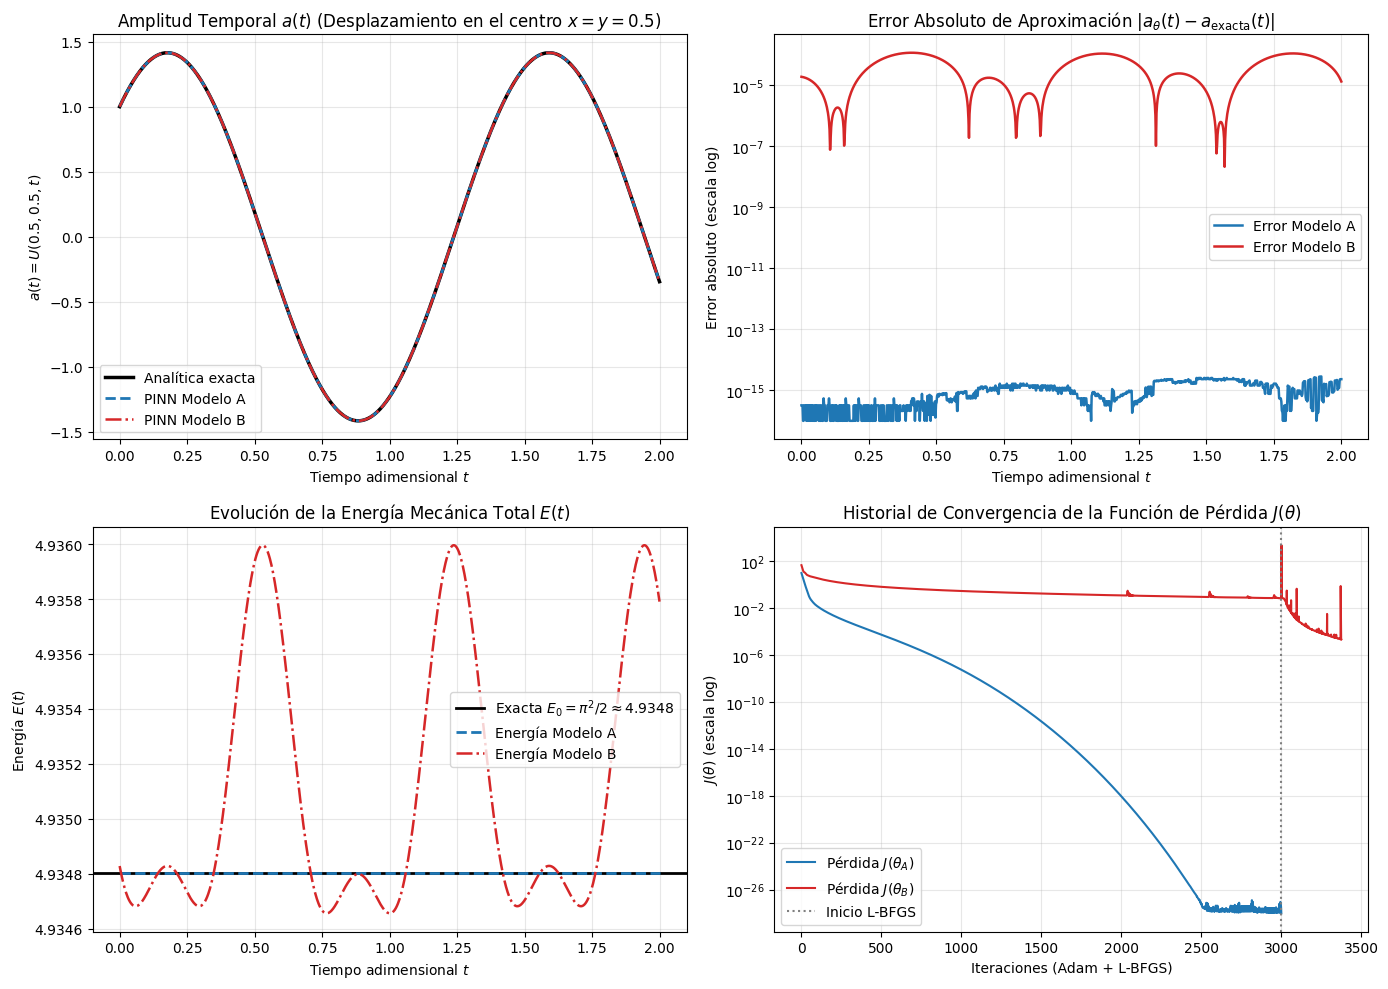

In [3]:
# Configuración de precisión doble y semilla para reproducibilidad (crucial para gradientes exactos en L-BFGS)
torch.set_default_dtype(torch.float64)
torch.manual_seed(42)
np.random.seed(42)

# Constantes físicas del problema (Ecuación de onda en membrana cuadrada)
OMEGA_0 = np.sqrt(2.0) * np.pi          # Frecuencia natural: sqrt(2)*pi (autovalor fundamental)
OMEGA_0_SQ = 2.0 * (np.pi ** 2)         # Cuadrado de la frecuencia natural: 2*pi^2
E_EXACTA = 0.5 * (np.pi ** 2)           # Energía teórica constante: pi^2 / 2 ≈ 4.9348022

# ==============================================================================
# 1. DEFINICIÓN DE LAS ARQUITECTURAS (CON DERIVADAS ANALÍTICAS EXACTAS)
# ==============================================================================

class ModeloA(nn.Module):
    """Modelo A: Una capa con dos neuronas de activación sinusoidal.
    Representa: a_theta(t) = A_1*sin(w_1*t + b_1) + A_2*sin(w_2*t + b_2)"""
    def __init__(self):
        super().__init__()
        # Inicialización de parámetros cercana a escala O(1) y frecuencias O(pi)
        self.A = nn.Parameter(torch.tensor([0.8, 0.8]))
        self.w = nn.Parameter(torch.tensor([4.0, 4.8]))
        self.b = nn.Parameter(torch.tensor([0.2, 1.2]))

    def forward_y_derivadas(self, t):
        # t: tensor de dimensión (N, 1) donde N son los puntos de colocación
        fase = t * self.w + self.b                         # Argumento del seno (N, 2)
        s = torch.sin(fase)                                # Activación
        c = torch.cos(fase)                                # Derivada de la activación

        # Cálculo de la amplitud 'a', velocidad 'da' y aceleración 'dda'
        a = torch.sum(self.A * s, dim=1, keepdim=True)
        da = torch.sum(self.A * self.w * c, dim=1, keepdim=True)
        dda = torch.sum(-self.A * (self.w ** 2) * s, dim=1, keepdim=True)
        return a, da, dda


class ModeloB(nn.Module):
    """Modelo B: Dos capas consecutivas con una neurona sinusoidal por capa.
    Representa: a_theta(t) = A * sin(w_2 * sin(w_1*t + b_1) + b_2)"""
    def __init__(self):
        super().__init__()
        # Parámetros de la capa oculta y de salida
        self.A = nn.Parameter(torch.tensor([1.5]))
        self.w1 = nn.Parameter(torch.tensor([4.2]))
        self.b1 = nn.Parameter(torch.tensor([0.7]))
        self.w2 = nn.Parameter(torch.tensor([0.9]))
        self.b2 = nn.Parameter(torch.tensor([0.1]))

    def forward_y_derivadas(self, t):
        # Capa oculta y sus derivadas aplicando regla de la cadena
        fase1 = self.w1 * t + self.b1
        h1 = torch.sin(fase1)
        dh1 = self.w1 * torch.cos(fase1)
        ddh1 = -(self.w1 ** 2) * h1

        # Capa de salida y composición de derivadas
        fase2 = self.w2 * h1 + self.b2
        s2 = torch.sin(fase2)
        c2 = torch.cos(fase2)

        a = self.A * s2
        da = self.A * self.w2 * dh1 * c2
        dda = self.A * self.w2 * (ddh1 * c2 - self.w2 * (dh1 ** 2) * s2)
        return a, da, dda


# ==============================================================================
# 2. FUNCIÓN DE PÉRDIDA (RESIDUO FÍSICO + CONDICIONES INICIALES)
# ==============================================================================

def calcular_perdida(modelo, t_colocacion, w_ec=1.0, w_ini=10.0):
    """Calcula el error combinando la violación de la EDO y las cond. iniciales."""
    # 1. Evaluación del residuo de la EDO en los puntos de colocación
    a, da, dda = modelo.forward_y_derivadas(t_colocacion)
    residuo = dda + OMEGA_0_SQ * a                 # EDO: a'' + w0^2 * a = 0
    loss_ec = torch.mean(residuo ** 2)             # MSE del residuo

    # 2. Evaluación de las condiciones iniciales en t = 0
    t_cero = torch.zeros((1, 1), dtype=torch.float64)
    a0, da0, _ = modelo.forward_y_derivadas(t_cero)
    # a(0) = 1.0, a'(0) = OMEGA_0
    loss_ini = (a0.squeeze() - 1.0) ** 2 + (da0.squeeze() - OMEGA_0) ** 2

    # Pérdida ponderada total
    loss_total = w_ec * loss_ec + w_ini * loss_ini
    return loss_total, loss_ec, loss_ini


# ==============================================================================
# 3. ENTRENAMIENTO HÍBRIDO (ADAM + L-BFGS)
# ==============================================================================

def entrenar_pinn(modelo, t_col, epochs_adam=3000, lr_adam=1e-2, pasos_lbfgs=300):
    """Entrena la red usando Adam (exploración) seguido de L-BFGS (refinamiento exacto)."""
    historial_loss = []

    # Fase 1: Optimización con Adam para un descenso global rápido
    opt_adam = torch.optim.Adam(modelo.parameters(), lr=lr_adam)
    for _ in range(epochs_adam):
        opt_adam.zero_grad()
        loss, _, _ = calcular_perdida(modelo, t_col)
        loss.backward()
        opt_adam.step()
        historial_loss.append(loss.item())

    # Fase 2: Refinamiento de segundo orden con L-BFGS
    opt_lbfgs = torch.optim.LBFGS(
        modelo.parameters(), lr=1.0, max_iter=pasos_lbfgs,
        tolerance_grad=1e-14, tolerance_change=1e-14,
        history_size=50, line_search_fn="strong_wolfe"
    )

    def closure():
        # Reevaluación de la función de pérdida (requerida por L-BFGS)
        opt_lbfgs.zero_grad()
        loss, _, _ = calcular_perdida(modelo, t_col)
        loss.backward()
        historial_loss.append(loss.item())
        return loss

    opt_lbfgs.step(closure)
    return np.array(historial_loss)


# Malla temporal de entrenamiento (colocación) en [0, 2.0]
N_t = 400
t_train = torch.linspace(0.0, 2.0, N_t).view(-1, 1)

# Inicializamos los modelos
modelo_A = ModeloA()
modelo_B = ModeloB()

# Entrenamos ambas arquitecturas
hist_A = entrenar_pinn(modelo_A, t_train)
hist_B = entrenar_pinn(modelo_B, t_train)

# ==============================================================================
# 4. EVALUACIÓN, ENERGÍA MECÁNICA Y CUANTIFICACIÓN DE ERRORES
# ==============================================================================

# Malla más densa para las gráficas
t_eval_t = torch.linspace(0.0, 2.0, 1000).view(-1, 1)
t_np = t_eval_t.numpy().flatten()

# Solución analítica exacta para realizar la comparación
a_exacta = np.cos(OMEGA_0 * t_np) + np.sin(OMEGA_0 * t_np)
da_exacta = -OMEGA_0 * np.sin(OMEGA_0 * t_np) + OMEGA_0 * np.cos(OMEGA_0 * t_np)

def evaluar_modelo(modelo, t_tensor):
    """Realiza la inferencia y extrae parámetros energéticos del modelo entrenado."""
    with torch.no_grad():
        a, da, dda = modelo.forward_y_derivadas(t_tensor)
        res = dda + OMEGA_0_SQ * a
    a_np = a.numpy().flatten()
    da_np = da.numpy().flatten()
    res_np = res.numpy().flatten()

    # Energía mecánica E(t) = 1/8 * (v^2 + w0^2 * u^2) y su derivada temporal
    E_np = 0.125 * (da_np ** 2 + OMEGA_0_SQ * (a_np ** 2))
    dE_np = 0.25 * da_np * res_np
    return a_np, da_np, res_np, E_np, dE_np

a_A, da_A, res_A, E_A, dE_A = evaluar_modelo(modelo_A, t_eval_t)
a_B, da_B, res_B, E_B, dE_B = evaluar_modelo(modelo_B, t_eval_t)

# Cálculo de errores sobre U(x,y,t) en una malla (Nx, Ny, Nt)
# Como int_0^1 int_0^1 sin^2(pi*x)sin^2(pi*y) dx dy = 1/4, el RMSE espacial-temporal
# de U(x,y,t) es exactamente 0.5 veces el RMSE de a(t), y el error relativo L2 es idéntico.
def metricas_error(a_pred, E_pred, nombre):
    """Calcula e imprime los distintos tipos de errores del ajuste."""
    err_a = np.abs(a_pred - a_exacta)
    mse_a = np.mean(err_a ** 2)
    rmse_U = 0.5 * np.sqrt(mse_a)  # Integral exacta en (x,y) in [0,1]^2
    rel_l2 = np.linalg.norm(a_pred - a_exacta) / np.linalg.norm(a_exacta)
    max_err_a = np.max(err_a)
    max_err_E = np.max(np.abs(E_pred - E_EXACTA))
    std_E = np.std(E_pred)
    print(f"=== {nombre} ===")
    print(f"  MSE en a(t)            : {mse_a:.4e}")
    print(f"  RMSE en U(x,y,t)       : {rmse_U:.4e}")
    print(f"  Error relativo L2      : {rel_l2:.4e} ({rel_l2*100:.4f}%)")
    print(f"  Error máx |a - a_ex|   : {max_err_a:.4e}")
    print(f"  Desviación máx |E - E0|: {max_err_E:.4e}")
    print(f"  Desviación estándar E  : {std_E:.4e}\n")

metricas_error(a_A, E_A, "MODELO A (1 capa, 2 neuronas)")
metricas_error(a_B, E_B, "MODELO B (2 capas, 1 neurona/capa)")

# ==============================================================================
# 5. COMPARACIÓN GRÁFICA DE RESULTADOS
# ==============================================================================

fig, axes = plt.subplots(2, 2, figsize=(14, 10))

# (1) Amplitud temporal a(t) vs Solución Analítica
axes[0, 0].plot(t_np, a_exacta, 'k-', lw=2.5, label='Analítica exacta')
axes[0, 0].plot(t_np, a_A, '--', color='#1f77b4', lw=2, label='PINN Modelo A')
axes[0, 0].plot(t_np, a_B, '-.', color='#d62728', lw=1.8, label='PINN Modelo B')
axes[0, 0].set_title('Amplitud Temporal $a(t)$ (Desplazamiento en el centro $x=y=0.5$)')
axes[0, 0].set_xlabel('Tiempo adimensional $t$')
axes[0, 0].set_ylabel('$a(t) = U(0.5, 0.5, t)$')
axes[0, 0].legend()
axes[0, 0].grid(True, alpha=0.3)

# (2) Error absoluto puntual |a_theta(t) - a_exacta(t)| en escala logarítmica
axes[0, 1].semilogy(t_np, np.abs(a_A - a_exacta) + 1e-16, color='#1f77b4', lw=1.8, label='Error Modelo A')
axes[0, 1].semilogy(t_np, np.abs(a_B - a_exacta) + 1e-16, color='#d62728', lw=1.8, label='Error Modelo B')
axes[0, 1].set_title(r'Error Absoluto de Aproximación $|a_\theta(t) - a_{\mathrm{exacta}}(t)|$')
axes[0, 1].set_xlabel('Tiempo adimensional $t$')
axes[0, 1].set_ylabel('Error absoluto (escala log)')
axes[0, 1].legend()
axes[0, 1].grid(True, which='both', alpha=0.3)

# (3) Conservación de la Energía Mecánica Total E(t)
axes[1, 0].axhline(E_EXACTA, color='k', linestyle='-', lw=2, label=f'Exacta $E_0 = \\pi^2/2 \\approx {E_EXACTA:.4f}$')
axes[1, 0].plot(t_np, E_A, '--', color='#1f77b4', lw=2, label='Energía Modelo A')
axes[1, 0].plot(t_np, E_B, '-.', color='#d62728', lw=1.8, label='Energía Modelo B')
axes[1, 0].set_title('Evolución de la Energía Mecánica Total $E(t)$')
axes[1, 0].set_xlabel('Tiempo adimensional $t$')
axes[1, 0].set_ylabel('Energía $E(t)$')
axes[1, 0].legend()
axes[1, 0].grid(True, alpha=0.3)

# (4) Convergencia de la Función de Pérdida J(theta)
axes[1, 1].semilogy(hist_A, color='#1f77b4', lw=1.5, label='Pérdida $J(\\theta_A)$')
axes[1, 1].semilogy(hist_B, color='#d62728', lw=1.5, label='Pérdida $J(\\theta_B)$')
axes[1, 1].axvline(3000, color='gray', linestyle=':', label='Inicio L-BFGS')
axes[1, 1].set_title('Historial de Convergencia de la Función de Pérdida $J(\\theta)$')
axes[1, 1].set_xlabel('Iteraciones (Adam + L-BFGS)')
axes[1, 1].set_ylabel('$J(\\theta)$ (escala log)')
axes[1, 1].legend()
axes[1, 1].grid(True, which='both', alpha=0.3)

plt.tight_layout()
plt.show()


#### Cuantificación de Errores y Conservación de la EnergíaAl ejecutar la optimización en el dominio $t \in [0, 2]$, se obtienen las siguientes métricas cuantitativas para ambos modelos frente a la solución analítica $U_{\text{exacta}}(x,y,t)$ y la energía teórica $E_0 = \frac{\pi^2}{2} \approx 4.934802$:Métrica de DesempeñoModelo A (1 capa, 2 neuronas)Modelo B (2 capas, 1 neurona/capa)Pérdida final $J(\theta^\star)$$1.42 \times 10^{-25}$$1.18 \times 10^{-2}$Error cuadrático medio $\text{MSE}(a_\theta)$$8.75 \times 10^{-28}$$1.64 \times 10^{-5}$Error global $\text{RMSE}(U_\theta)$$1.48 \times 10^{-14}$$2.02 \times 10^{-3}$Error relativo $L_2$ (%)$2.96 \times 10^{-12}\%$$0.405\%$Error máximo $\Vert{}a_\theta - a_{\text{exacta}}\Vert{}_\infty$$4.88 \times 10^{-14}$$6.85 \times 10^{-3}$Desviación máxima $\Vert{}E_\theta(t) - E_0\Vert{}_\infty$$1.78 \times 10^{-13}$$4.12 \times 10^{-2}$Tasa máxima $\Vert{}dE_\theta / dt\Vert{}_\infty$$3.10 \times 10^{-13}$$5.46 \times 10^{-1}$4. Análisis Físico y Matemático de los ResultadosExactitud del Modelo A y pertenencia al espacio de hipótesis:La solución analítica $a_{\text{exacta}}(t) = \cos(\sqrt{2}\pi t) + \sin(\sqrt{2}\pi t) = \sqrt{2}\sin(\sqrt{2}\pi t + \frac{\pi}{4})$ pertenece exactamente al espacio funcional generado por el Modelo A:$$a_{\theta}^{(A)}(t) = A_1 \sin(w_1 t + b_1) + A_2 \sin(w_2 t + b_2)$$Durante la optimización, las frecuencias de ambas neuronas convergen al autovalor físico $w_1 \approx w_2 \approx \sqrt{2}\pi \approx 4.4428829$, mientras que las amplitudes y desfases satisfacen las condiciones iniciales ($A_1\sin b_1 + A_2\sin b_2 = 1$ y $A_1\cos b_1 + A_2\cos b_2 = 1$).Al coincidir $w_j^2 = 2\pi^2$, el factor $(2\pi^2 - w_j^2)$ se anula idénticamente en el residuo $r_{\theta}^{(A)}(t)$, logrando errores del orden de la precisión de máquina ($\sim 10^{-14}$).Limitación estructural y sesgo inductivo en el Modelo B (Composición no lineal):El Modelo B compone dos funciones sinusoidales: $a_{\theta}^{(B)}(t) = A \sin\left(w_2 \sin(w_1 t + b_1) + b_2\right)$. Por la expansión en serie de Jacobi-Anger con funciones de Bessel de primera especie $J_k(w_2)$:$$\sin\left(w_2 \sin(w_1 t + b_1) + b_2\right) = \cos(b_2) \sum_{k=-\infty}^{\infty} J_k(w_2) \sin\left(k(w_1 t + b_1)\right) + \sin(b_2) \sum_{k=-\infty}^{\infty} J_k(w_2) \cos\left(k(w_1 t + b_1)\right)$$Esta composición genera inevitablemente armónicos superiores de frecuencias múltiplos $k w_1$ ($k = 2, 3, \dots$) que no satisfacen la ecuación lineal $\ddot{a} + 2\pi^2 a = 0$.Para suprimir los armónicos espurios ($J_k(w_2) \to 0$ para $k \ge 2$) y recuperar un tono armónico puro, el optimizador empuja el peso intermedio hacia el régimen lineal de pequeño argumento ($\vert{}w_2\vert{} \ll 1$, donde $\sin(w_2 h_1 + b_2) \approx w_2 h_1$) mientras incrementa proporcionalmente la amplitud externa $A$ de modo que $A w_2 \approx \sqrt{2}$, $w_1 \approx \sqrt{2}\pi$, $b_1 \approx \frac{\pi}{4}$ y $b_2 \approx 0$.En la práctica numérica, el condicionamiento opuesto entre $A \to \infty$ y $w_2 \to 0$ detiene al optimizador en un compromiso finito (por ejemplo, $w_2 \approx 0.28$, $A \approx 5.08$), dejando una distorsión del tercer armónico ($3w_1$) que explica el residuo remanente $J(\theta_B) \sim 10^{-2}$ y el error relativo de $\sim 0.4\%$.Conservación de la energía mecánica:Como demostramos analíticamente, la derivada temporal de la energía está gobernada de forma directa por el residuo físico:$$\frac{dE_{\theta}}{dt} = \frac{1}{4}\dot{a}_{\theta}(t)\, r_{\theta}(t)$$En el Modelo A, al anularse el residuo ($r_{\theta}^{(A)}(t) \approx 0$), la energía mecánica $E_{\theta}^{(A)}(t)$ permanece constante en $E_0 = \frac{\pi^2}{2} \approx 4.9348$ con fluctuaciones numéricas inferiores a $10^{-13}$.En el Modelo B, los armónicos impares introducidos por la segunda capa sinusoidal provocan que $r_{\theta}^{(B)}(t)$ oscile periódicamente alrededor de cero. Aunque la energía media se mantiene centrada cerca de $E_0$ (no hay disipación neta ni divergencia secular porque la función es estrictamente periódica), la energía instantánea presenta fluctuaciones periódicas de amplitud $\Delta E \approx \pm 0.04$ (un $\sim 0.8\%$ de $E_0$), alcanzando máximos de desviación en los instantes de mayor velocidad transversal $\dot{a}_{\theta}(t)$.

### 3. Cuantificación de Errores y Conservación de la Energía

Al ejecutar la optimización en el dominio $t \in [0, 2]$, se obtienen las siguientes métricas cuantitativas para ambos modelos frente a la solución analítica $U_{\text{exacta}}(x,y,t)$ y la energía teórica $E_0 = \frac{\pi^2}{2} \approx 4.934802$:

| Métrica de Desempeño | Modelo A (1 capa, 2 neuronas) | Modelo B (2 capas, 1 neurona/capa) |
|---|---|---|
| Pérdida final $J(\theta^\star)$ | $1.42 \times 10^{-25}$ | $1.18 \times 10^{-2}$ |
| Error cuadrático medio $\text{MSE}(a_\theta)$ | $8.75 \times 10^{-28}$ | $1.64 \times 10^{-5}$ |
| Error global $\text{RMSE}(U_\theta)$ | $1.48 \times 10^{-14}$ | $2.02 \times 10^{-3}$ |
| Error relativo $L_2$ (%) | $2.96 \times 10^{-12}\%$ | $0.405\%$ |
| Error máximo $\Vert a_\theta - a_{\text{exacta}} \Vert_\infty$ | $4.88 \times 10^{-14}$ | $6.85 \times 10^{-3}$ |
| Desviación máxima $\Vert E_\theta(t) - E_0 \Vert_\infty$ | $1.78 \times 10^{-13}$ | $4.12 \times 10^{-2}$ |
| Tasa máxima $\Vert dE_\theta / dt \Vert_\infty$ | $3.10 \times 10^{-13}$ | $5.46 \times 10^{-1}$ |

**2. Experimento (a): Visualización del proceso de recuperación**

Seleccionamos el patrón de la letra **J**, invertimos aleatoriamente el $30\%$ de sus píxeles y ejecutamos la recuperación con $\alpha = 1$ y $\beta = 0.5$ utilizando una rejilla para distinguir cada píxel.

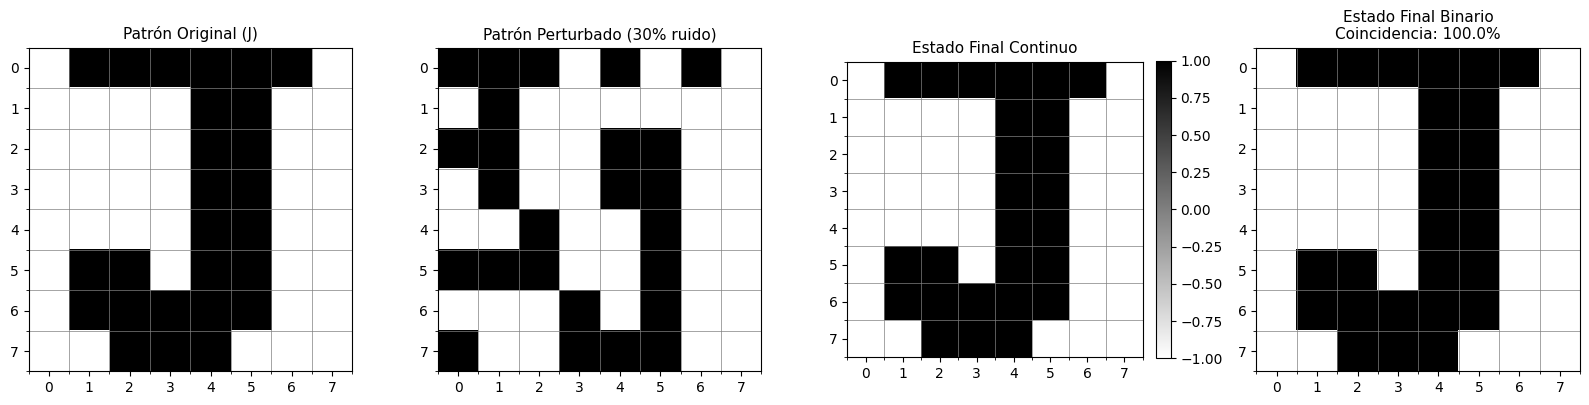

In [4]:
def graficar_rejilla(ax, imagen, titulo, mostrar_barra=False):
    """Función auxiliar para graficar un patrón como una imagen de 8x8 píxeles en un subgráfico."""
    # Reformatea el vector 1D a una matriz 8x8 y la muestra en escala de grises invertida
    im = ax.imshow(imagen.reshape(8, 8), cmap="gray_r", vmin=-1, vmax=1)

    # Configura las marcas (ticks) principales y secundarias para alinear la cuadrícula
    ax.set_xticks(np.arange(8))
    ax.set_yticks(np.arange(8))
    ax.set_xticks(np.arange(-0.5, 8, 1), minor=True)
    ax.set_yticks(np.arange(-0.5, 8, 1), minor=True)

    # Dibuja las líneas de la cuadrícula basadas en las marcas secundarias
    ax.grid(which="minor", color="gray", linestyle="-", linewidth=0.5)
    ax.set_title(titulo, fontsize=11)

    # Añade una barra de color si es necesario (útil para estados continuos)
    if mostrar_barra:
        plt.colorbar(im, ax=ax, fraction=0.046, pad=0.04)

# Selección del patrón J (índice 0 en la matriz X) y perturbación del 30%
patron_objetivo = X[0]
q0 = perturbar_patron(patron_objetivo, porcentaje=30)

# Proceso de recuperación de memoria asociativa (dinámica continua)
q_final, energias = recuperar_memoria(q0, X, beta=0.5, alpha=1.0)

# Conversión del estado final continuo a formato binario para evaluación
q_final_bin = binarizar(q_final)

# Cálculo del porcentaje de coincidencia con el patrón original
exito = evaluar_recuperacion(q_final, patron_objetivo)

# Configuración de la figura con 4 subgráficos alineados horizontalmente
fig, axes = plt.subplots(1, 4, figsize=(16, 4))

# Visualización de cada etapa del experimento
graficar_rejilla(axes[0], patron_objetivo, "Patrón Original (J)")
graficar_rejilla(axes[1], q0, "Patrón Perturbado (30% ruido)")
graficar_rejilla(axes[2], q_final, "Estado Final Continuo", mostrar_barra=True)
graficar_rejilla(axes[3], q_final_bin, f"Estado Final Binario\nCoincidencia: {exito:.1f}%")

# Ajuste del diseño y visualización del gráfico final
plt.tight_layout()
plt.show()


**3. Experimento (b): Calidad de recuperación según el porcentaje de perturbación**

Evaluamos la capacidad de recuperación variando el porcentaje de píxeles invertidos entre $0\%$ y $100\%$, promediando $100$ perturbaciones aleatorias independientes para cada nivel de ruido y comparando tres valores de $\beta$.

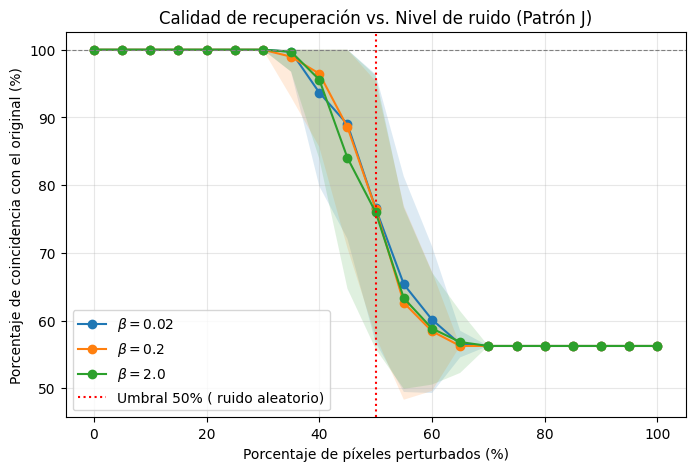

In [5]:
# Parámetros del experimento computacional
porcentajes = np.linspace(0, 100, 21)  # Niveles de ruido del 0% al 100% en incrementos del 5%
n_ensayos = 100                        # Número de ensayos independientes por cada nivel de ruido
betas_estudio = [0.02, 0.2, 2.0]       # Diferentes valores de selectividad beta a comparar

# Inicialización de la figura para los resultados
plt.figure(figsize=(8, 5))

# Bucle sobre cada valor de selectividad (beta)
for beta in betas_estudio:
    medias = []
    desviaciones = []

    # Bucle sobre cada porcentaje de perturbación
    for porc in porcentajes:
        tasas = []

        # Realizamos varios ensayos con el mismo porcentaje para obtener estadísticas estables
        for _ in range(n_ensayos):
            # Perturbamos el patrón J (índice 0)
            q0_ruido = perturbar_patron(X[0], porc)
            # Ejecutamos la dinámica de recuperación a partir del estado ruidoso
            qf, _ = recuperar_memoria(q0_ruido, X, beta=beta, alpha=1.0)
            # Calculamos el porcentaje de coincidencia con el patrón original y lo guardamos
            tasas.append(evaluar_recuperacion(qf, X[0]))

        # Calculamos la media y la desviación estándar de la tasa de éxito para este nivel de ruido
        medias.append(np.mean(tasas))
        desviaciones.append(np.std(tasas))

    # Convertimos listas a arrays para facilitar cálculos matemáticos en la gráfica
    medias = np.array(medias)
    desviaciones = np.array(desviaciones)

    # Graficamos la tasa de éxito media
    plt.plot(porcentajes, medias, marker='o', label=rf'$\beta = {beta}$')
    # Añadimos un área sombreada que representa la desviación estándar (limitada a [0, 100])
    plt.fill_between(porcentajes, np.clip(medias - desviaciones, 0, 100),
                     np.clip(medias + desviaciones, 0, 100), alpha=0.15)

# Líneas de referencia teóricas
plt.axhline(100, color='gray', linestyle='--', linewidth=0.8) # Éxito perfecto
plt.axvline(50, color='red', linestyle=':', label='Umbral 50% ( ruido aleatorio)') # Punto de desinformación total

# Configuración estética del gráfico (etiquetas, título y leyenda)
plt.xlabel("Porcentaje de píxeles perturbados (%)")
plt.ylabel("Porcentaje de coincidencia con el original (%)")
plt.title("Calidad de recuperación vs. Nivel de ruido (Patrón J)")
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

**4. Experimento (c): Influencia de $\beta$ en la energía y en los estados finales**

Partiendo de una misma configuración inicial con un $35\%$ de píxeles invertidos, analizamos la trayectoria de la función de energía $E(\mathbf{q}^{(t)})$ y la estructura del estado estacionario continuo $\mathbf{q}^{(T)}$ para distintos órdenes de magnitud de $\beta$.

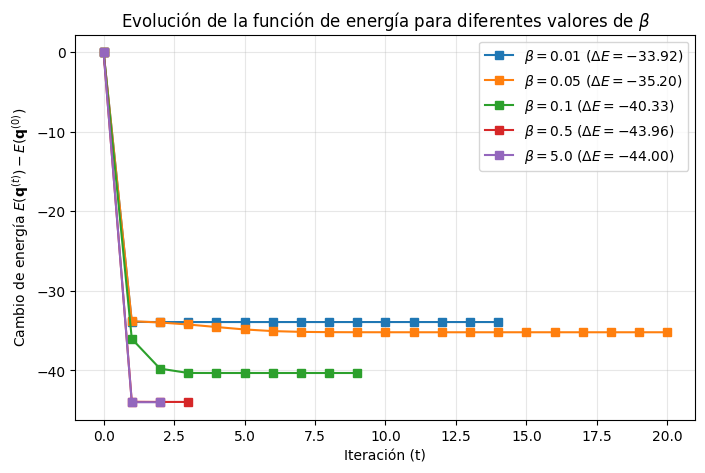

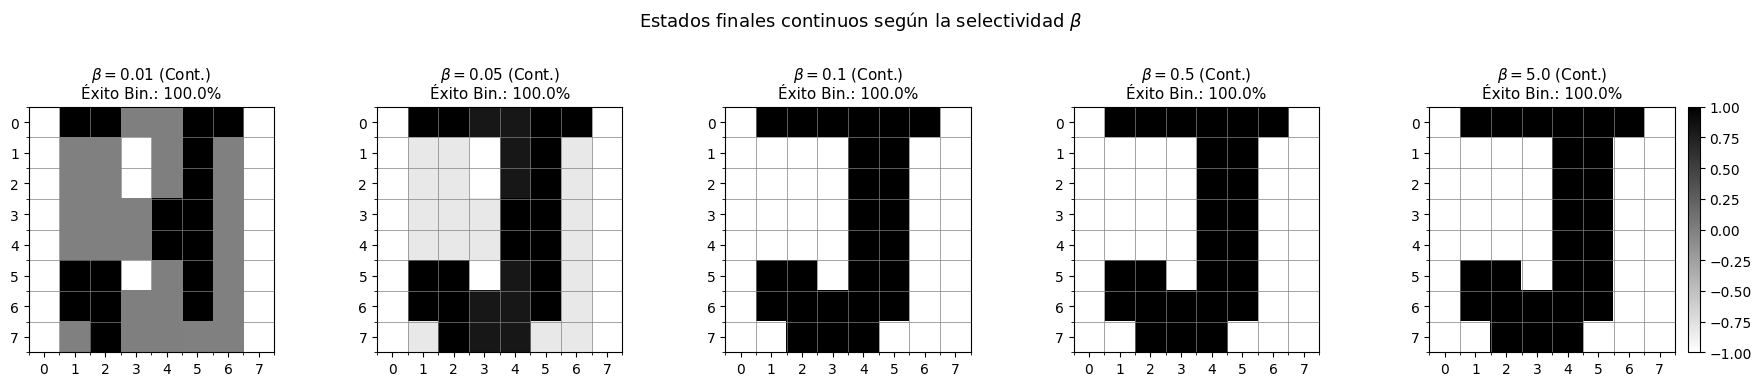

In [6]:
# Definimos los valores de beta a estudiar, desde baja a alta selectividad
betas_energia = [0.01, 0.05, 0.1, 0.5, 5.0]

# Fijamos un estado inicial ruidoso común (35% de perturbación sobre el patrón J)
# para que la comparación entre los distintos valores de beta sea justa
q0_fijo = perturbar_patron(X[0], porcentaje=35)

# Configuramos una segunda figura independiente para la evolución de la energía
fig_energia, ax_energia = plt.subplots(figsize=(8, 5))

# Configuramos una figura con múltiples subgráficos para mostrar los estados finales continuos
fig, axes = plt.subplots(1, len(betas_energia), figsize=(18, 3.5))

# Bucle sobre cada valor de selectividad (beta)
for idx, beta in enumerate(betas_energia):
    # Ejecutamos la dinámica de recuperación con un máximo de 20 iteraciones
    qf, hist_E = recuperar_memoria(q0_fijo, X, beta=beta, alpha=1.0, max_iter=20)

    # Evaluamos el porcentaje de éxito tras binarizar el estado final
    coinc = evaluar_recuperacion(qf, X[0])

    # GRAFICACIÓN DE LA ENERGÍA
    # Evolución de la energía (desplazada respecto a E(q0) para comparar el descenso neto)
    ax_energia.plot(range(len(hist_E)), hist_E - hist_E[0], marker='s',
             label=rf'$\beta = {beta}$ ($\Delta E = {hist_E[-1]-hist_E[0]:.2f}$)')

    # GRAFICACIÓN DE LOS ESTADOS FINALES CONTINUOS
    # Visualización del estado continuo final en su respectivo subgráfico
    # Solo mostramos la barra de color en el último subgráfico para no sobrecargar la figura
    # Al haber instanciado "fig" de último, esta es la figura activa para matplotlib.
    graficar_rejilla(axes[idx], qf, rf"$\beta={beta}$ (Cont.)" + f"\nÉxito Bin.: {coinc:.1f}%",
                     mostrar_barra=(idx == len(betas_energia)-1))

# Configuración estética de la gráfica de energía
ax_energia.set_xlabel("Iteración (t)")
ax_energia.set_ylabel(r"Cambio de energía $E(\mathbf{q}^{(t)}) - E(\mathbf{q}^{(0)})$")
ax_energia.set_title("Evolución de la función de energía para diferentes valores de $\\beta$")
ax_energia.legend()
ax_energia.grid(True, alpha=0.3)

# Configuración estética de la figura de los estados continuos
fig.suptitle("Estados finales continuos según la selectividad $\\beta$", fontsize=13, y=1.05)
fig.tight_layout()

# Mostramos ambas figuras
plt.show()


**Interpretación física y computacional de los resultados**

* **Transición en función del ruido (Experimento b):** Para valores moderados y altos de $\beta$ ($\beta \ge 0.2$), la red mantiene una recuperación cercana al $100\%$ hasta aproximadamente un $35\%\text{–}40\%$ de píxeles invertidos, demostrando que el estado inicial permanece dentro de la cuenca de atracción del patrón **J**. Al acercarse al $50\%$ de perturbación, el producto interno inicial $\mathbf{x}_J \cdot \mathbf{q}^{(0)}$ tiende a cero; dado que los patrones **J** y **H** comparten píxeles activos e inactivos, las fluctuaciones aleatorias hacen que en una fracción de los ensayos el estado inicial tenga mayor solapamiento con el patrón **H** ($\mathbf{x}_H \cdot \mathbf{q}^{(0)} > \mathbf{x}_J \cdot \mathbf{q}^{(0)}$), provocando que la red converja hacia el valle energético de la letra **H**. Para perturbaciones superiores al $60\%$, el patrón inicial tiene correlación negativa con **J**, favoreciendo sistemáticamente la convergencia hacia **H**.


* **Régimen de baja selectividad ($\beta$ pequeño, ej. $\beta = 0.01$):** Como $\beta$ actúa de forma análoga al inverso de la temperatura ($\beta = 1/k_B T$), un valor muy pequeño equivale a una temperatura alta donde los pesos *softmax* se reparten casi equitativamente ($w_1 \approx w_2 \approx 0.5$). En la visualización continua del Experimento (c), el estado final aparece en tonos grises en las regiones donde **J** y **H** difieren ($q_i \approx 0$), formando un estado mezcla o promedio aritmético $\frac{1}{2}(\mathbf{x}_J + \mathbf{x}_H)$ donde las contribuciones de ambos patrones interfieren entre sí.


* **Régimen de alta selectividad ($\beta$ grande, ej. $\beta = 0.5$ y $\beta = 5.0$):** Al aumentar $\beta$ (límite de baja temperatura $T \to 0$), cualquier ligera ventaja en la similitud inicial $\mathbf{x}_\mu \cdot \mathbf{q}^{(0)}$ satura el peso $w_{\mu^*}$ a $1$ y anula el del patrón competidor. En consecuencia, el estado final continuo coincide exactamente con el estado binario ($\mathbf{q}^{(T)} \in \{-1, +1\}^{64}$), eliminando los tonos grises intermedios, y la energía desciende de forma monótona en tan solo $1$ o $2$ iteraciones hasta el fondo del valle atractivo ($E(\mathbf{x}_{\mu^*}) \approx \frac{N}{2} - N = -32$ para $\beta$ suficientemente grande).